# Objectif 

Date de création : 05/05/2026

Illustration de la structure du module des RTFs dans le plan (f, r)

## Cadre de l'étude 

Le guide d'onde étudié est un guide d'onde idéal avec fond parfaitement rigide aux dimensions approximative de l'environnement de la Groix. 

* Profondeur : $D = 30$ m.
* Antenne HLA de deux capteurs, immersion fixe 1 mètre au-dessus du fond $z_a = 29$ m.
* Source d'immersion fixe $z_s = 5$ m, distance au capteur de référence r variable. 
* Environnement : guide d'onde idéal (fond parfaitement solide). 

## Rappel formulation modale 

On pose 
$$
    Q =  \frac{e^{i3\pi/4}}{\rho(z_s) \sqrt{8 \pi}}
$$

et

$$
    A_m(z) = \Psi_m(z_{s}) \Psi_m(z) \frac{1}{\sqrt{k_{rm}}}
$$

La fonction de transfert du guide d'onde s'écrit,

$$
    H(f, r, z) = \frac{Q}{\sqrt{r}} \sum_{m=1}^{\infty} A_m(z) e^{-ik_{rm}
    r}
$$

En particulier, la fonction de transfert du canal de propagation associée au récepteur $j$ est :

$$
    H_{j} = \frac{Q}{\sqrt{r_j}} \sum_{m=1}^{\infty} A_m(z_j) e^{-ik_{rm}
    r_{j}}
$$

on s'intéresse au vecteur de RTF défini par

$$
    \mathbf{\Pi} \overset{\Delta}{=}
    \left [ \frac{H_{1}}{H_{1}} \, \frac{H_{2}}{H_{1}} \, \dots \, \frac{H_{M}}{H_{1}} \right ]^T
    = \frac{1}{H_{1}} \mathbf{H}
$$

Ici, il n'y a que deux capteurs et on s'intéresse simplement au rapport :

$$
    \Pi_2 = \frac{H_2}{H_1}
$$

**Conditions aux limites (cas parfaitement solide -> perfectly_rigid)**

Pression nulle en surface et au fond :
$$
p(r, z=0) = 0 \quad \text{et} \quad \frac{\partial p(r, z)}{\partial z} \rvert_{z=D} = 0 
$$

et les fonctions modales s'écrivent 

$$
\Psi_m(z) = \sqrt{\frac{2 \rho}{D}} \sin(k_{zm} z)
$$

Les fonctions $\Psi_m$ sont les fonctions propres associées aux valeurs propres $k_{rm}$,

$$
    k_{rm} = \sqrt{ k^2 - k_{zm}^2}
$$

avec, 

$$ 
    k_{zm} =  (m - \frac{1}{2}) \frac{\pi}{D}, \quad m \in \mathbb{N}^{*} .
$$

Le nombre $M$ de modes propagatifs (i.e correspondant à des k_{rm} réels) est donné par :

$$
    M = \left \lfloor \frac{\omega D}{c \pi} + \frac{1}{2}\right \rfloor
$$


In [2]:
# %matplotlib ipympl

import os
import sys
import numpy as np
import xarray as xr
import scipy.signal as sp
import matplotlib.pyplot as plt

from scipy.fft import rfft, rfftfreq
from scipy.signal import find_peaks


sys.path.append(r"C:\Users\baptiste.menetrier\Desktop\devPy\phd")

# from misc import mult_along_axis
from real_data_analysis.fiberscope_groix.src.localisation.rtf.sensibility.simu.sensi_simu_utils import (
    run_full_study,
    compute_rtf_dataset,
    plot_intensity,
    plot_tl_pi_frequency_range_plan,
    get_dist
)

# from propa.rtf.rtf_utils import D_hermitian_angle_fast
import source.global_constants as g
from publication.publication_figure import (
    PubFigure,
    LargeFigure,
    SmallFigure,
    color,
    set_subfigures_abc_labels,
)

In [3]:
root_img = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\img\illustration\interference_structure"

# Définition du guide d'onde 

On considère la gamme de fréquence étudiée en actif [400, 800] Hz. La distance inter-capteurs est fixée à 950 m correspondant approximativement à la distance entre OBS 3 et OBS 2. 
La position de la source varie de 5 à 995 m (par rapport au capteur 1, cf schéma).  

In [4]:
bottom_bc = "perfectly_rigid"
# bottom_bc = "pressure_release"
waveguide_depth = 30
d_inter_rcv = 950
z_rcv = 29
# src_ref_range = 1.15 * 1e3
dr = 0.5
src_ref_range = 10 * 1e3
z_src = 5
delta_r = 5000
nrgrid = int(np.ceil(2 * delta_r / dr)) + 1
fmin = 400
fmax = 800
nfgrid = 500

print(2 * delta_r / (nrgrid - 1))

0.5


In [5]:
omega_max = 2 * np.pi * fmax
c = 1500
M = np.floor((omega_max*waveguide_depth/(np.pi*c)) + 1/2).astype(int)
print("Nombre maximal de modes propagatifs M = ", M)

Nombre maximal de modes propagatifs M =  32


In [6]:
distances=["hermitian_angle"]
m = 4
ds = run_full_study(
    bottom_bc=bottom_bc,
    waveguide_depth=waveguide_depth,
    d_inter_rcv=d_inter_rcv,
    z_rcv=z_rcv,
    src_ref_range=src_ref_range,
    z_src=z_src,
    nrgrid=nrgrid,
    delta_r=delta_r,
    fmin=fmin,
    fmax=fmax,
    nfgrid=nfgrid,
    root_img=root_img,
    distances=distances,
    n_modes=m,
)

Number of propagating modes at fmin = 400 Hz : 16
Number of propagating modes at fmax = 800 Hz : 32
Computing RTF using  M = 4 modes (instead of all the propagating modes which are 32 at fmax)


Dataset computed


In [7]:
I_1 = np.abs(4 * np.pi * ds.H1) ** 2
I_2 = np.abs(4 * np.pi * ds.H2) ** 2
I_1_dB = -10 * np.log10(I_1 + 1e-12)
I_2_dB = -10 * np.log10(I_2 + 1e-12)
rtf2_mod = ds.module.sel(h_index=2)
rtf2_mod_log = 10 * np.log10(rtf2_mod)
gamma = 10 * np.log10(rtf2_mod**2)

(<Figure size 1800x1200 with 6 Axes>,
 array([<Axes: title={'center': '$\\text{TL}_1(r, f) = -10 \\log_{10}(\\lvert 4 \\pi H_1(f, r) \\rvert^2)$'}>,
        <Axes: title={'center': '$\\text{TL}_2(r, f) = -10 \\log_{10}(\\lvert 4 \\pi H_2(f, r) \\rvert^2)$'}>,
        <Axes: title={'center': '$10 \\log_{10} \\left( \\lvert \\Pi_2(f, r) \\rvert^2 \\right) =  \\text{TL}_1(r, f) - \\text{TL}_2(r, f) $'}>],
       dtype=object))

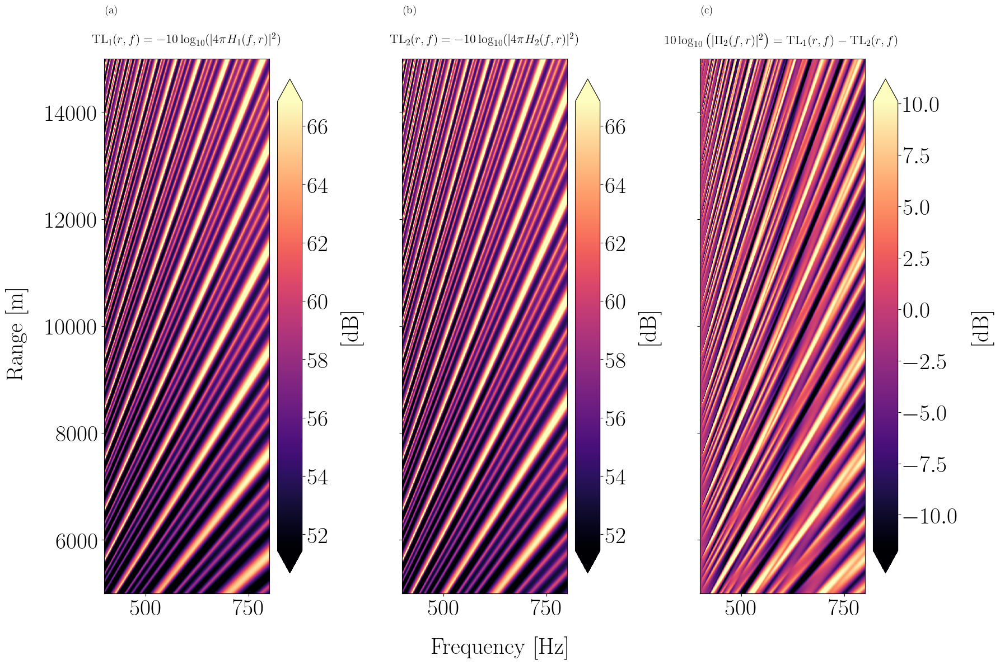

In [8]:
plot_tl_pi_frequency_range_plan(I_1_dB, I_2_dB, rtf2_mod, x_coord="f", y_coord="r")

In [9]:
ds

<xarray.Dataset> Size: 480MB
Dimensions:   (f: 500, r: 20001, h_index: 2)
Coordinates:
  * f         (f) float64 4kB 400.0 400.8 401.6 402.4 ... 798.4 799.2 800.0
  * r         (r) float64 160kB 5e+03 5e+03 5.001e+03 ... 1.5e+04 1.5e+04
  * h_index   (h_index) int64 16B 1 2
Data variables:
    H1        (f, r) complex64 80MB (-0.00015258265-3.0529227e-05j) ... (3.31...
    H2        (f, r) complex64 80MB (-4.206495e-05+0.000117971475j) ... (-4.9...
    data      (h_index, f, r) complex64 160MB (1+0j) ... (0.12116463-0.478220...
    phase     (h_index, f, r) float32 80MB 0.0 0.0 0.0 ... -1.308 -1.315 -1.323
    module    (h_index, f, r) float32 80MB 1.0 1.0 1.0 ... 0.487 0.4901 0.4933
    data_ref  (h_index, f) complex64 8kB (1+0j) ... (-0.21056354-0.655166j)
    nb_modes  (f) int64 4kB 16 16 16 16 16 16 16 16 ... 32 32 32 32 32 32 32 32
Attributes:
    description:      RTF dataset for an ideal waveguide. The antenna is comp...
    bottom_bc:        perfectly_rigid
    waveguide_depth:  30
    z_s:              5
    z_a:              29
    r_ref:            10000.0
    d12:              950
    h_index_ref:      1

# Filtrage dans le plan (f, k)


L'objectif est d'extraire l'information associée aux interférences modales de grandes longueurs d'ondes (i.e à des petits $\Delta_{k{mn}}$) afin d'obtenir un lobe principal plus large permettant la mise en œuvre, en pratique de la méthode.

Pour se faire on applique une transformée de Fourier le long de l'axe r et on applique un filtre passe bas dans le domaine des nombres d'ondes. La distance $\theta$ est ensuite calculée sur les signaux filtrés. 

## Filtrage sur l'ensemble des positions 

Afin d'illustrer on commence par appliquer la transformée de Fourier en espace sur l'ensemble des échantillons. 

In [10]:
from propa.ideal_waveguide import kr, kz
modes = np.arange(1, m + 1)
f = ds.f.values 

delta_kmns = np.zeros((m, m, len(f)))
lambda_mns = np.zeros((m, m, len(f)))
# j = 0
for i_m in range(m):
    for i_n in range(i_m + 1, m):
        delta_kmn = kr(modes[i_m], f, waveguide_depth, bottom_bc=bottom_bc) - kr(
            modes[i_n], f, waveguide_depth, bottom_bc=bottom_bc
        )
        delta_kmns[i_m, i_n, :] = delta_kmn

        lambda_mn = 2 * np.pi / delta_kmn
        lambda_mns[i_m, i_n, :] = lambda_mn

        # j+=1

# plt.legend()
# plt.xlabel("Frequency [Hz]")
# plt.ylabel(r"$\Delta_{k_{mn}}\, [\text{m}^{-1}]$")

# plt.figure()
# j = 0
# for i_m in range(m):
#     for i_n in range(i_m + 1, m):
#         delta_kmn = kr(modes[i_m], f, waveguide_depth, bottom_bc=bottom_bc) - kr(
#             modes[i_n], f, waveguide_depth, bottom_bc=bottom_bc
#         )
#         lambda_mn = 2*np.pi / delta_kmn
#         plt.plot(f, lambda_mn, label=f"m={modes[i_m]}, n={modes[i_n]}", color=color(j))
#         j += 1

# plt.legend()
# plt.xlabel("Frequency [Hz]")
# plt.ylabel(r"$\lambda_{mn}$ [m]")

Text(0, 0.5, '$\\Delta_{k_{mn}}\\, [\\text{m}^{-1}]$')

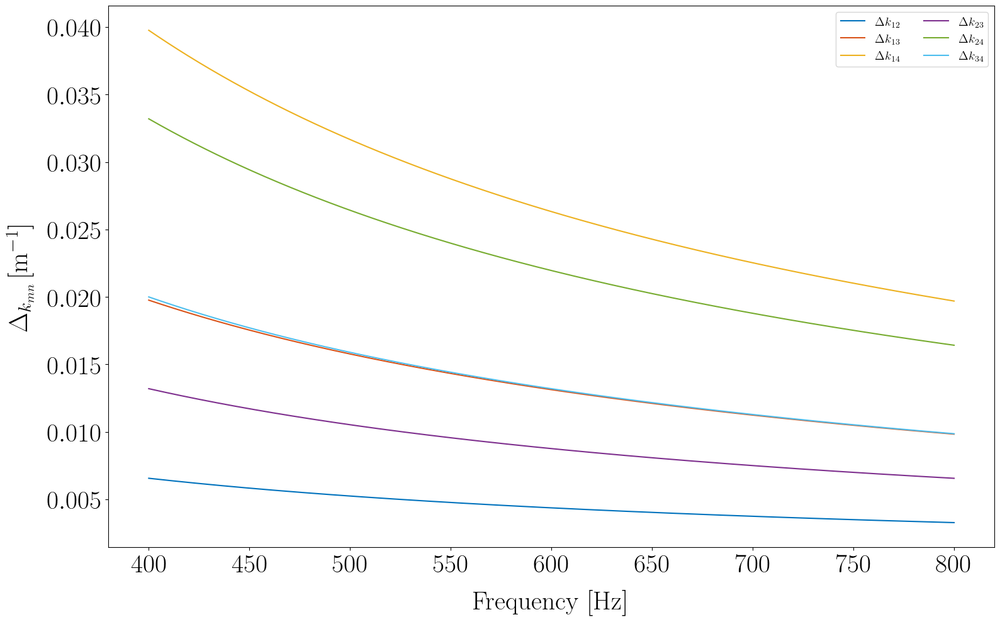

In [11]:
plt.figure()
ax = plt.gca()

j = 0
for i_m in range(m):
    for i_n in range(i_m + 1, m):
        delta_kmn = delta_kmns[i_m, i_n, :]
        ax.plot(
            f,
            delta_kmn,
            label=rf"$\Delta k_{{{modes[i_m]}{modes[i_n]}}}$",
            color=color(j),
        )
        j += 1
    ax.legend(ncol=2)
    ax.set_ylabel("")
    ax.set_xlabel("")
    # ax.set_title(f"m = {modes[i_m]}")

plt.xlabel("Frequency [Hz]")
plt.ylabel(r"$\Delta_{k_{mn}}\, [\text{m}^{-1}]$")

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_18080\1996116902.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(ncol=2)


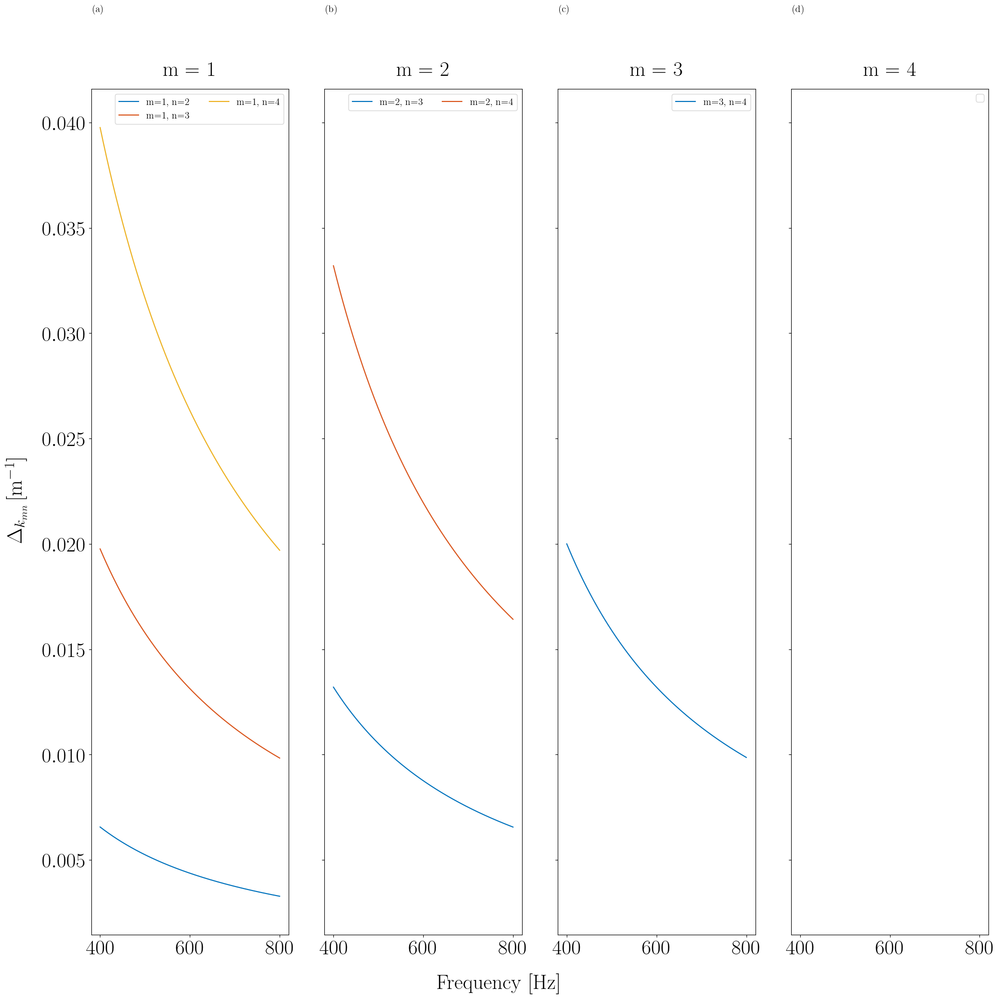

In [12]:
# Plot k_mn using panels, on panel per m
ncol = 4
nrow = len(modes) // 4 + 1 if len(modes) % 4 != 0 else len(modes) // 4
fig, axs = plt.subplots(nrow, ncol, figsize=(20, 20), sharex=True, sharey=True)
axs = axs.flatten()

for i_m in range(m):
    ax = axs[i_m]
    j = 0
    for i_n in range(i_m + 1, m):
        delta_kmn = delta_kmns[i_m, i_n, :]
        ax.plot(f, delta_kmn, label=f"m={modes[i_m]}, n={modes[i_n]}", color=color(j))
        j += 1
    ax.legend(ncol=2)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_title(f"m = {modes[i_m]}")

fig.supxlabel("Frequency [Hz]")
fig.supylabel(r"$\Delta_{k_{mn}}\, [\text{m}^{-1}]$")

set_subfigures_abc_labels(axs, x_pos=0.005, y_pos=1.1, fontsize=14)

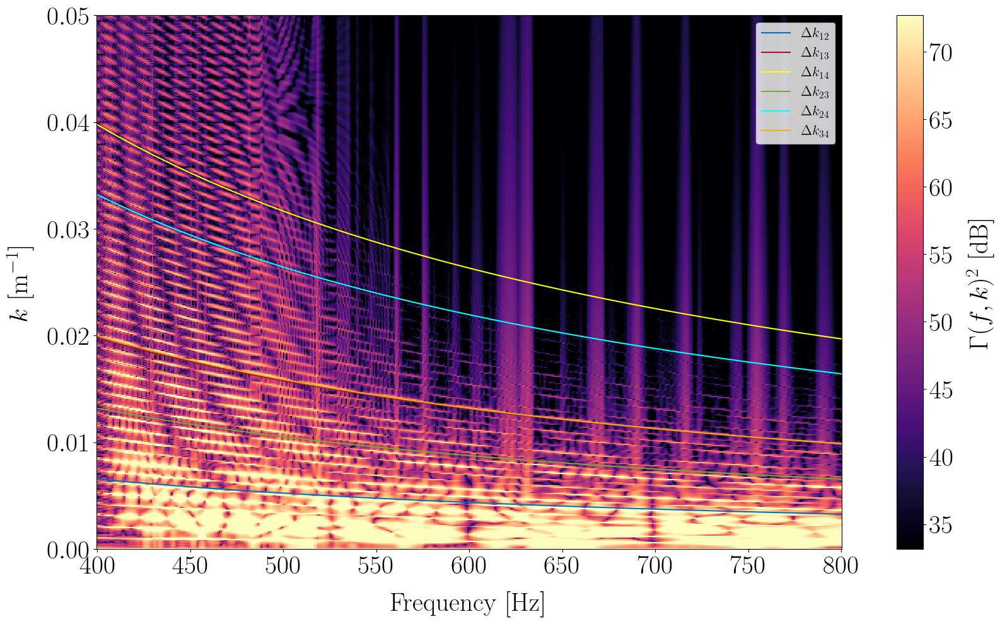

In [13]:
# Apply FFT along the r dimension
dr = ds.r.values[1] - ds.r.values[0]
gamma_fft = np.fft.rfft(gamma, axis=1)
k = np.fft.rfftfreq(I_1_dB.shape[1], d=dr)  #
k_lim = 0.05

k_index = np.where(k < k_lim)[0]
gamma_fft_under_lim = gamma_fft[:, k_index]
k_under_lim = k[k_index]

plt.figure()
# I_1_dB_fft_show = np.abs(I_1_dB_fft)
# I_1_dB_fft_show = I_1_dB_fft_show[:, k < 0.175]
# k_show = k[k < 0.175]
gamma_spectro = 20 * np.log10(np.abs(gamma_fft_under_lim).T)
vmin = np.percentile(np.abs(gamma_spectro), 25)
vmax = np.percentile(np.abs(gamma_spectro), 95)
plt.pcolormesh(
    ds.f.values,
    k_under_lim,
    gamma_spectro,
    cmap="magma",
    vmax=vmax,
    vmin=vmin,
)


j = 0
for i_m in range(m):
    for i_n in range(i_m + 1, m):
        delta_kmn = delta_kmns[i_m, i_n, :]

        if np.min(delta_kmn) < k_lim:
            # delta_kmn_0 = 1/13* delta_kmn
            couple=f"{modes[i_m]}{modes[i_n]}"
            # plt.plot(f, 1*delta_kmn_0, color=color(j+1), linestyle="--", label=fr"${{{1}}}\Delta k_{{{couple}}}$")
            # plt.plot(f, 2*delta_kmn_0, color=color(j+2), linestyle="--", label=fr"${{{2}}}\Delta k_{{{couple}}}$")
            # plt.plot(f, 3*delta_kmn_0, color=color(j+3), linestyle="--", label=fr"${{{3}}}\Delta k_{{{couple}}}$")
            # plt.plot(f, 4*delta_kmn_0, color=color(j+4), linestyle="--", label=fr"${{{4}}}\Delta k_{{{couple}}}$")
            # plt.plot(f, 5*delta_kmn_0, color=color(j+5), linestyle="--", label=fr"${{{5}}}\Delta k_{{{couple}}}$")

            plt.plot(f, delta_kmn, color=color(j), linestyle="-", label=fr"$\Delta k_{{{couple}}}$")

        j += 6

        # for i_p in range(m):
        #     for i_q in range(i_p + 1, m):
        #         delta_kpq = delta_kmns[i_p, i_q, :]

        #         delta_mnpq_1 = delta_kmn + delta_kpq
        #         delta_mnpq_2 = - delta_kmn - delta_kpq
        #         delta_mnpq_3 = delta_kmn - delta_kpq
        #         delta_mnpq_4 = - delta_kmn + delta_kpq

        #         if np.min(delta_mnpq_1) < k_lim:
        #             plt.plot(
        #                 f,
        #                 delta_mnpq_1,
        #                 color=color(j),
        #                 linestyle="-",
        #                 # label=rf"$\Delta k_{{{modes[i_m]}{modes[i_n]}}} + \Delta k_{{{modes[i_p]}{modes[i_q]}}}$",
        #             )
        #         if np.min(delta_mnpq_2) < k_lim:
        #             plt.plot(
        #                 f,
        #                 delta_mnpq_2,
        #                 color=color(j),
        #                 linestyle="--",
        #                 # label=rf"$- \Delta k_{{{modes[i_m]}{modes[i_n]}}} - \Delta k_{{{modes[i_p]}{modes[i_q]}}}$",
        #             )
        #         if np.min(delta_mnpq_3) < k_lim:
        #             plt.plot(
        #                 f,
        #                 delta_mnpq_3,
        #                 color=color(j),
        #                 linestyle="--",
        #                 # label=rf"$\Delta k_{{{modes[i_m]}{modes[i_n]}}} - \Delta k_{{{modes[i_p]}{modes[i_q]}}}$",
        #             )
        #         if np.min(delta_mnpq_4) < k_lim:
        #             plt.plot(
        #                 f,
        #                 delta_mnpq_4,
        #                 color=color(j),
        #                 linestyle="--",
        #                 # label=rf"$- \Delta k_{{{modes[i_m]}{modes[i_n]}}} + \Delta k_{{{modes[i_p]}{modes[i_q]}}}$",
        #             )
        #         j += 1

plt.colorbar(label=r"$\Gamma(f, k)^2$ [dB]")
# plt.legend(ncol=8, fontsize=8)
plt.legend(fontsize=16)
plt.xlabel("Frequency [Hz]")
plt.ylabel(r"$k~[\text{m}^{-1}]$")
plt.ylim(0, k_lim)

fpath = os.path.join(root_img, f"gamma_spectro_M_{m}.png")
plt.savefig(fpath, dpi=300)

In [14]:
bottom_bc = "perfectly_rigid"
# bottom_bc = "pressure_release"
waveguide_depth = 30
d_inter_rcv = 950
z_rcv = 29
# src_ref_range = 1.15 * 1e3
dr = 0.5
src_ref_range = 500
z_src = 5
delta_r = 495
nrgrid = int(np.ceil(2 * delta_r / dr)) + 1
fmin = 400
fmax = 800
nfgrid = 500

print(2 * delta_r / (nrgrid - 1))

0.5


In [15]:
distances=["hermitian_angle"]
m = 16
ds = run_full_study(
    bottom_bc=bottom_bc,
    waveguide_depth=waveguide_depth,
    d_inter_rcv=d_inter_rcv,
    z_rcv=z_rcv,
    src_ref_range=src_ref_range,
    z_src=z_src,
    nrgrid=nrgrid,
    delta_r=delta_r,
    fmin=fmin,
    fmax=fmax,
    nfgrid=nfgrid,
    root_img=root_img,
    distances=distances,
    n_modes=m,
)

Number of propagating modes at fmin = 400 Hz : 16
Number of propagating modes at fmax = 800 Hz : 32
Computing RTF using  M = 16 modes (instead of all the propagating modes which are 32 at fmax)
Dataset computed


In [16]:
I_1 = np.abs(4 * np.pi * ds.H1) ** 2
I_2 = np.abs(4 * np.pi * ds.H2) ** 2
I_1_dB = -10 * np.log10(I_1 + 1e-12)
I_2_dB = -10 * np.log10(I_2 + 1e-12)
rtf2_mod = ds.module.sel(h_index=2)
rtf2_mod_log = 10 * np.log10(rtf2_mod)
gamma = 10 * np.log10(rtf2_mod**2)

(<Figure size 1800x1200 with 6 Axes>,
 array([<Axes: title={'center': '$\\text{TL}_1(r, f) = -10 \\log_{10}(\\lvert 4 \\pi H_1(f, r) \\rvert^2)$'}>,
        <Axes: title={'center': '$\\text{TL}_2(r, f) = -10 \\log_{10}(\\lvert 4 \\pi H_2(f, r) \\rvert^2)$'}>,
        <Axes: title={'center': '$10 \\log_{10} \\left( \\lvert \\Pi_2(f, r) \\rvert^2 \\right) =  \\text{TL}_1(r, f) - \\text{TL}_2(r, f) $'}>],
       dtype=object))

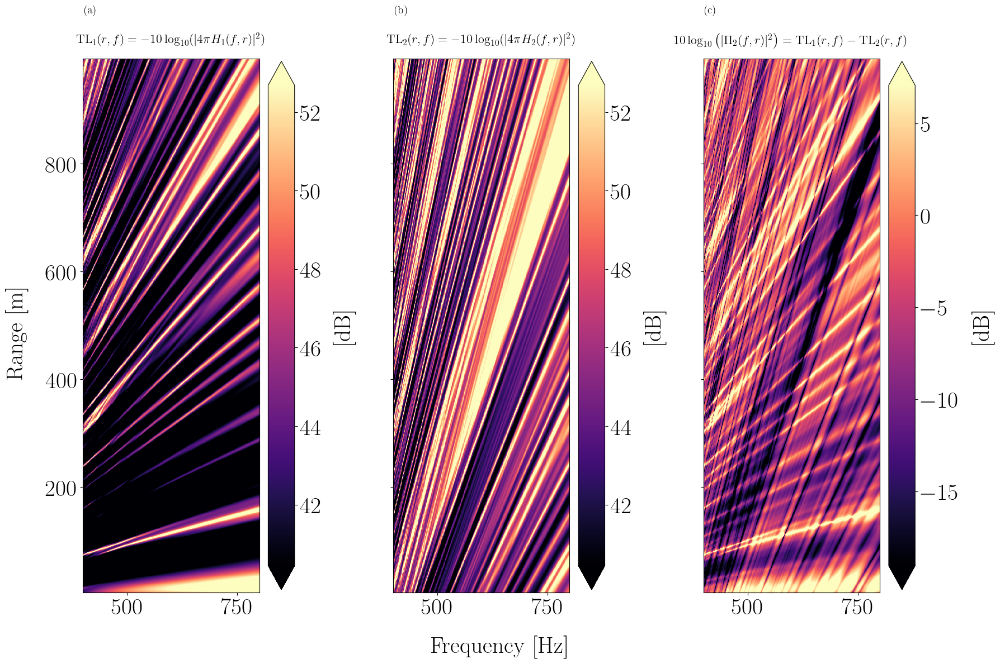

In [17]:
plot_tl_pi_frequency_range_plan(I_1_dB, I_2_dB, rtf2_mod, x_coord="f", y_coord="r")

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_18080\1012255226.py:37: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, dpi=300)


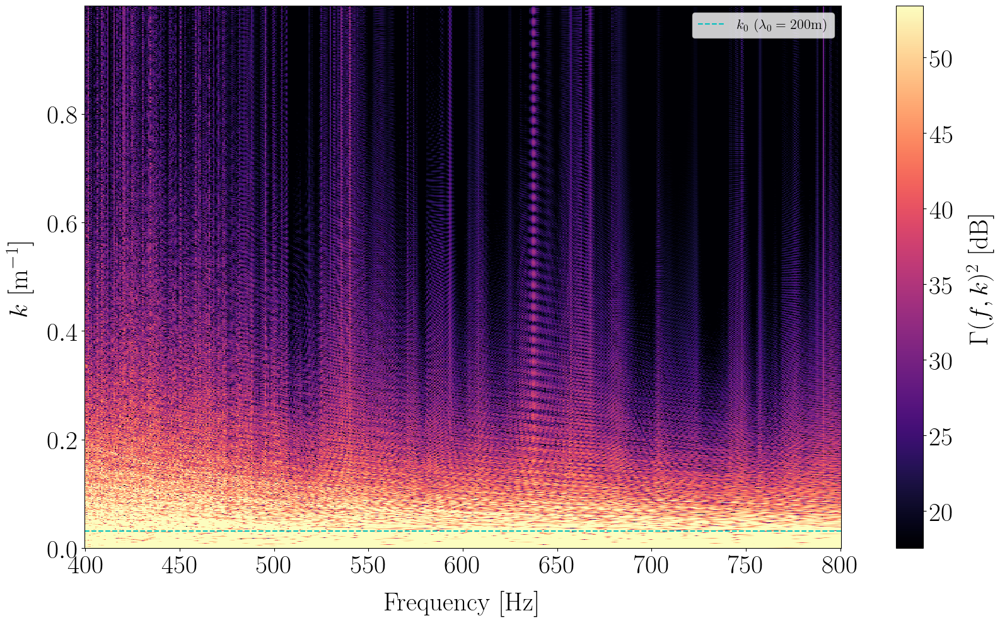

In [18]:
# Apply FFT along the r dimension
dr = ds.r.values[1] - ds.r.values[0]
gamma_fft = np.fft.rfft(gamma, axis=1)
k = np.fft.rfftfreq(I_1_dB.shape[1], d=dr)  #
k_lim = max(k)
l_0 = 200
k_max = 2 * np.pi / l_0


k_index = np.where(k < k_lim)[0]
gamma_fft_under_lim = gamma_fft[:, k_index]
k_under_lim = k[k_index]

plt.figure()
gamma_spectro = 20 * np.log10(np.abs(gamma_fft_under_lim).T)
vmin = np.percentile(np.abs(gamma_spectro), 25)
vmax = np.percentile(np.abs(gamma_spectro), 95)
plt.pcolormesh(
    ds.f.values,
    k_under_lim,
    gamma_spectro,
    cmap="magma",
    vmax=vmax,
    vmin=vmin,
)
plt.axhline(k_max, color="c", linestyle="--", label=fr"$k_0~(\lambda_0 = {{{l_0:.0f}}} \text{{m}})$")


plt.colorbar(label=r"$\Gamma(f, k)^2$ [dB]")
# plt.legend(ncol=8, fontsize=8)
plt.legend(fontsize=16)
plt.xlabel("Frequency [Hz]")
plt.ylabel(r"$k~[\text{m}^{-1}]$")
plt.ylim(0, k_lim)

fpath = os.path.join(root_img, f"gamma_spectro_M_{m}.png")
plt.savefig(fpath, dpi=300)

In [19]:
print(k_max)

0.031415926535897934


In [20]:
# Filter desired k
gamma_fft_filt = np.copy(gamma_fft)
gamma_fft_filt[:, k > k_max] = 0
gamma_filt = np.fft.irfft(gamma_fft_filt, n=gamma.shape[1], axis=1)

rtf2_mod_filt_xr = xr.zeros_like(rtf2_mod)
rtf2_mod_filt_xr.data = 10 ** (gamma_filt / 20)

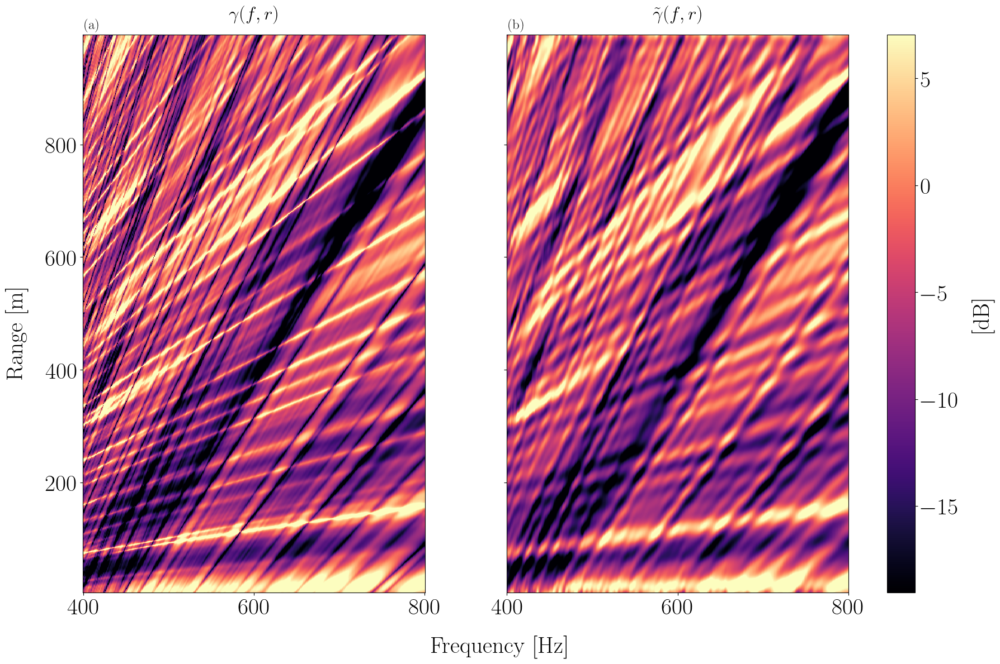

In [21]:
x_coord="f"
y_coord="r"

gamma_tilde = 10*np.log10(rtf2_mod_filt_xr**2)
fig, axs = plt.subplots(1, 2, figsize=(18, 12), sharex=True, sharey=True)

# vmin = max(np.percentile(intensity_1_dB, 5), np.percentile(intensity_2_dB, 5))
# vmax = min(np.percentile(intensity_1_dB, 95), np.percentile(intensity_2_dB, 95))
vmin = np.percentile(gamma, 5)
vmax = np.percentile(gamma, 95)

gamma.plot(
    ax=axs[0],
    x=x_coord,
    y=y_coord,
    cmap="magma",
    add_colorbar=False,
    # cbar_kwargs={
    #     # "label": r"$\text{TL}(r, f)$ [dB]",
    #     "label": "[dB]",
    # },
    vmin=vmin,
    vmax=vmax,
)
axs[0].set_title(
    r"$\gamma(f, r)$",
    fontsize=24,
)
axs[0].set_xlabel("")
axs[0].set_ylabel("")

im = gamma_tilde.plot(
    ax=axs[1],
    x=x_coord,
    y=y_coord,
    cmap="magma",
    add_colorbar=False,
    vmin=vmin,
    vmax=vmax,
)
axs[1].set_title(
    r"$\tilde{\gamma}(f, r)$",
    fontsize=24,
)
axs[1].set_xlabel("")
axs[1].set_ylabel("")

if x_coord == "r":
    fig.supxlabel("Range [m]")
    fig.supylabel("Frequency [Hz]")
elif x_coord == "f":
    fig.supylabel("Range [m]")
    fig.supxlabel("Frequency [Hz]")

set_subfigures_abc_labels(axs, x_pos=0.005, y_pos=1.03, fontsize=18)


clabel = r"[dB]"
fig.colorbar(
    im,
    ax=axs.ravel().tolist(),
    label=clabel,
    orientation="vertical",
    fraction=1.0,
    pad=0.03,
)

fpath = os.path.join(root_img, f"gamma_comparison_M_{m}_lmin_{l_0:.0f}m.png")
plt.savefig(fpath, dpi=300)

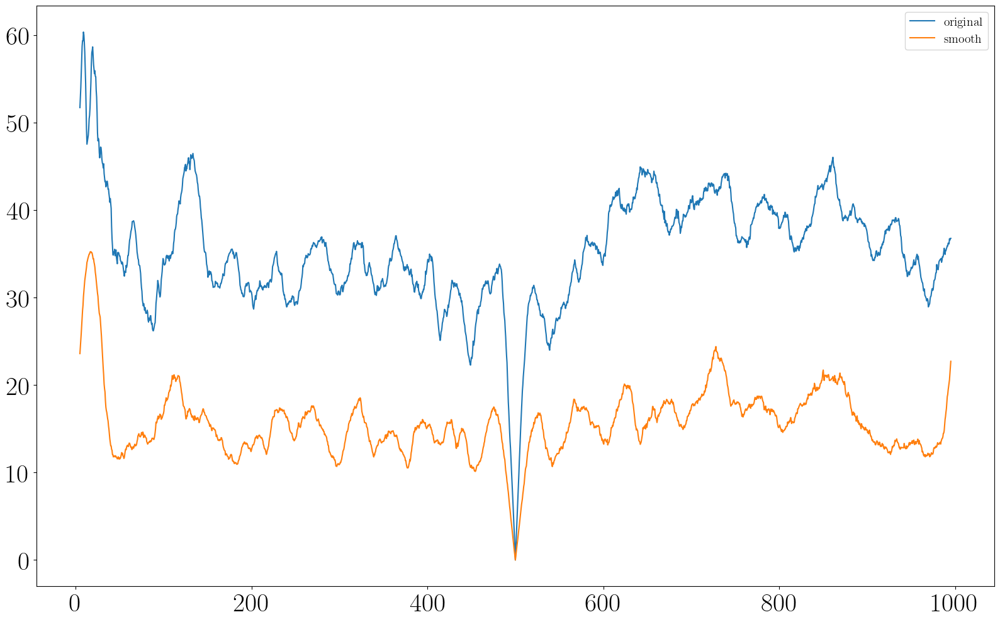

In [22]:
from real_data_analysis.fiberscope_groix.src.localisation.rtf.sensibility.simu.sensi_simu_utils import (
    get_dist,
    plot_distances_vs_range,
)

# Compute theta
dist1 = get_dist(ds, distances=distances)

# Plot theta vs range
r_grid_km = ds.r.values * 1e-3
# plot_distances_vs_range(r_grid_km, dist, root_fig="")

# Compute theta
ds_smooth = ds.copy()

rep = np.ones_like(ds_smooth.data)
rep[1, ...] = rtf2_mod_filt_xr.values
ds_smooth.data.data = rep
idx_r_ref = np.argmin(np.abs(ds.r.values - ds.r_ref))
ds_smooth.data_ref.data = rep[:, :, idx_r_ref]


dist2 = get_dist(ds_smooth, distances=distances)

plt.figure()
plt.plot(ds.r.values, dist1["hermitian_angle"]["d"], label="original")
plt.plot(ds.r.values, dist2["hermitian_angle"]["d"], label="smooth")
plt.legend()
plt.show()


In [23]:
# Iterate over potential l_0 values
window_size = 5 
l_0_values = np.arange(50, 600 + 50, 50)
results = []
results_smooth = []

for l_0 in l_0_values:
    # Define k max
    k_max = 2 * np.pi / l_0
    # Filter desired k
    gamma_fft_filt = np.copy(gamma_fft)
    gamma_fft_filt[:, k > k_max] = 0
    gamma_filt = np.fft.irfft(gamma_fft_filt, n=gamma.shape[1], axis=1)

    rtf2_mod_filt_xr = xr.zeros_like(rtf2_mod)
    rtf2_mod_filt_xr.data = 10 ** (gamma_filt / 20)

    # Compute distance
    ds_smooth = ds.copy()
    rep = np.ones_like(ds_smooth.data)
    rep[1, ...] = rtf2_mod_filt_xr.values
    ds_smooth.data.data = rep
    idx_r_ref = np.argmin(np.abs(ds.r.values - ds.r_ref))
    ds_smooth.data_ref.data = rep[:, :, idx_r_ref]
    dist_after_filter = get_dist(ds_smooth, distances=distances)
    dist = dist_after_filter["hermitian_angle"]["d"]
    dist_smooth = np.convolve(dist, np.ones(window_size) / window_size, mode="same")

    # Store results
    results.append(
        dist
    )
    results_smooth.append(
        dist_smooth
    )

    ds_smooth.close()
    del ds_smooth

results = np.array(results)

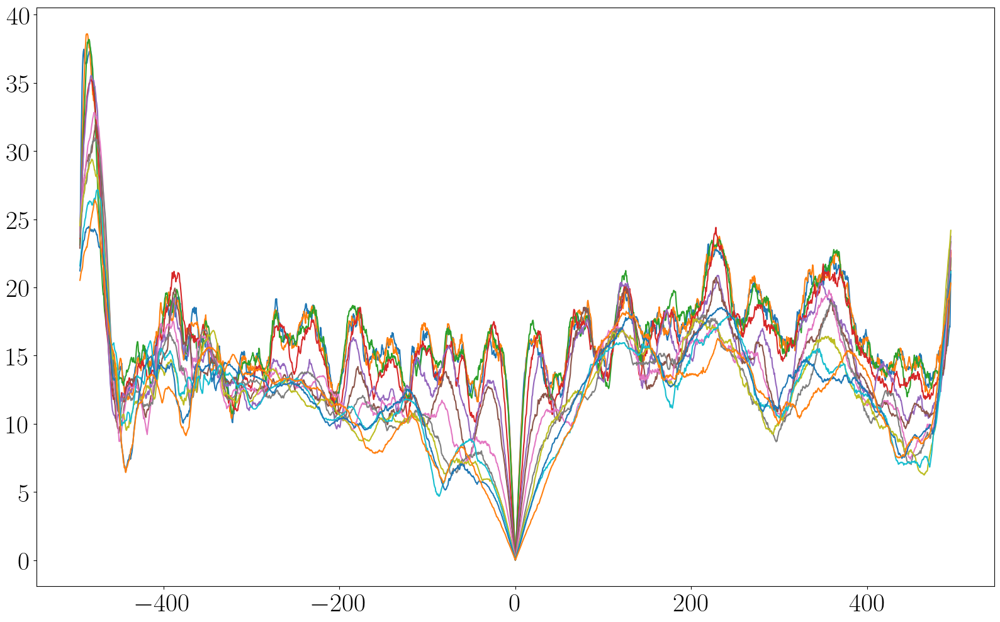

In [24]:
r_grid_shift = ds.r.values - ds.r_ref

plt.figure()
plt.plot(r_grid_shift, results.T)

In [25]:
# Define validity domain according to the first maximum of the distance (first zero crossing of the derivative)
r_validity_dict_zero_crossing = {}
r_th_zero_crossing_pos = {}
r_th_zero_crossing_neg = {}

for i_l_0, l_0 in enumerate(l_0_values):
    d = results[i_l_0, :]

    # Positive r - r0
    d_pos = d[r_grid_shift >= 0]
    r_pos = r_grid_shift[r_grid_shift >= 0]

    # Compute the derivative of the distance
    dd_dr_pos = np.gradient(d_pos, r_pos)
    # Find zero crossings of the derivative
    zero_crossings_pos = np.where(np.diff(np.sign(dd_dr_pos)))[0]
    if len(zero_crossings_pos) > 0:
        # Take the first zero crossing
        first_zero_crossing_pos = zero_crossings_pos[0]
        r_validity_zero_crossing_pos = r_pos[first_zero_crossing_pos]
        # Store the threshold corresponding to this zero crossing
        r_th_zero_crossing_pos[l_0] = r_validity_zero_crossing_pos

    # Negative r - r0
    d_neg = d[r_grid_shift < 0]
    r_neg = r_grid_shift[r_grid_shift < 0]
    dd_dr_neg = np.gradient(d_neg, r_neg)
    zero_crossings_neg = np.where(np.diff(np.sign(dd_dr_neg)))[0]
    if len(zero_crossings_neg) > 0:
        first_zero_crossing_neg = zero_crossings_neg[-1]
        r_validity_zero_crossing_neg = r_neg[first_zero_crossing_neg]
        # Store the threshold corresponding to this zero crossing
        r_th_zero_crossing_neg[l_0] = r_validity_zero_crossing_neg

    r_validity_zero_crossing = (
        r_validity_zero_crossing_pos - r_validity_zero_crossing_neg
    )
    # Store the validity range in the dictionary
    r_validity_dict_zero_crossing[l_0] = r_validity_zero_crossing

    print(f"l_0 = {l_0}m, first zero crossing at r={r_validity_zero_crossing:.2f} m")

l_0 = 50m, first zero crossing at r=31.00 m
l_0 = 100m, first zero crossing at r=27.00 m
l_0 = 150m, first zero crossing at r=33.00 m
l_0 = 200m, first zero crossing at r=41.50 m
l_0 = 250m, first zero crossing at r=49.50 m
l_0 = 300m, first zero crossing at r=46.50 m
l_0 = 350m, first zero crossing at r=61.00 m
l_0 = 400m, first zero crossing at r=65.50 m
l_0 = 450m, first zero crossing at r=61.00 m
l_0 = 500m, first zero crossing at r=74.00 m
l_0 = 550m, first zero crossing at r=83.50 m
l_0 = 600m, first zero crossing at r=143.50 m


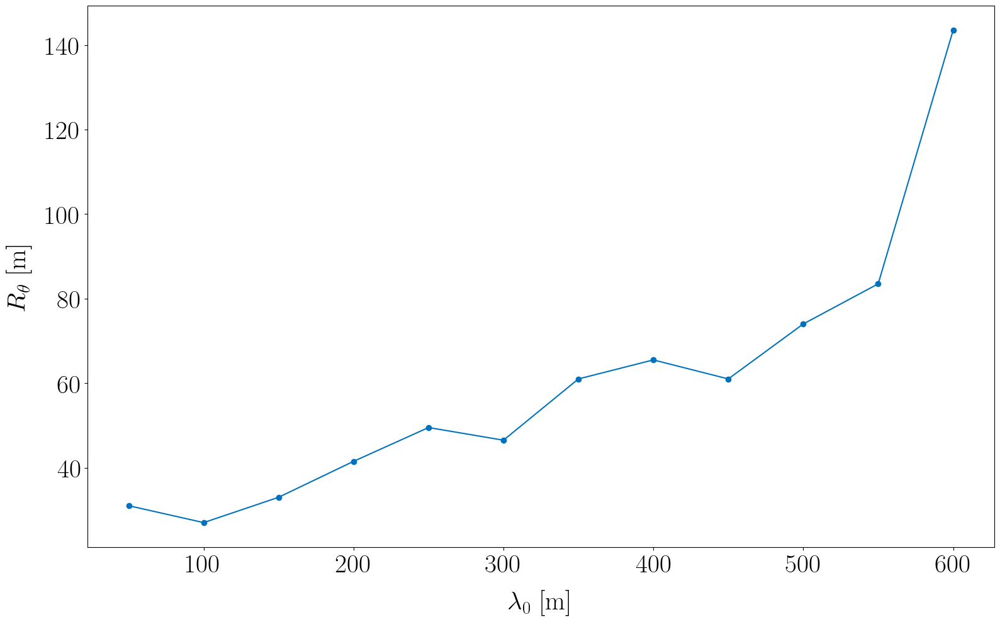

In [29]:
r_theta = [r_validity_dict_zero_crossing[l_0] for l_0 in l_0_values]
plt.figure()
plt.plot(l_0_values, r_theta, marker="o", color=color(0))

plt.xlabel(r"$\lambda_0$ [m]")
plt.ylabel(r"$R_\theta$ [m]")

fpath = os.path.join(root_img, f"validity_range_vs_lambda_0.png")
plt.savefig(fpath, dpi=300)

Plus le nombre d'onde de coupure $k_c$ est petit plus le lobe principal est large. Cet élargissement se fait au détriment du contraste. 

En pratique, les sources ne suivent pas nécessairement une trajectoire rectiligne alignée sur un couple de capteur. De plus, on souhaite conserver un contraste suffisant. Une approche intermédiaire consiste donc à appliquer la démarche précédente sur des fenêtres glissantes.   

## Filtrage glissant 

Dans la suite : 

* La séquence entière est découpée en $Q$ fenêtres notées $\left ( I_q \right )_{q \in [0, Q-1]}$.
* Chaque fenêtre $I_q$ contient les estimations de $2P + 1$ vecteurs de RTF (correspondant ici à $2P + 1$ positions $r_p$ successives).
* Le recouvrement entre les fenêtres $I_q$ est de $2P$ positions $r_p$ de sorte que la fenêtre glisse d'une unique position lorsque q augmente de 1.  

In [16]:
# Range step
dr = ds.r.values[1] - ds.r.values[0]
n_r = ds.r.size

# Define the size of the Iq windows
P = 100
n_overlap_I = 1
n_I = 2 * P + 1
size_I_r = n_I * dr

print(
    f"Selected window I size:  n_I = {n_I} samples (equivalent to L_I = {size_I_r:.1f}m)"
)

# Compute the number of I_q windows Q
Q = int(np.floor((n_r + n_overlap_I - n_I)/n_overlap_I))
print(f"Number of available segments I : Q = {Q}")

Selected window I size:  n_I = 201 samples (equivalent to L_I = 120.5m)
Number of available segments I : Q = 4801


### Choix du seuil de coupure $k_c$ 

#### Seuil défini en fonction de la longueur d'onde minimale

On définit le seuil $k_c$ en fonction de la longueur minimale que l'on souhaite conserver. 

* Plus $k_c$ est petit, plus les longueurs d'onde conservées sont grandes et donc plus le lobe principal est large. 
* Plus $k_c$ est grand, plus l'on préserve des motifs petite échelle et plus le lobe est étroit. 

La taille du lobe principale est également déterminé par la largeur de la fenêtre. 


ATTENTION : cette définition suppose que l'on connaisse l'échantillonnage spatial des positions (i.e $\Delta_r$) pour le calcul du vecteur de nombre d'onde k. En pratique, cette information est inconnue et le vecteur de k est arbitraire (i.e calculé avec d=1 dans le paramètre de la fonction rfftfreq).µ

In [17]:
# k_max = 0.005

k_win = 2 * np.pi / size_I_r    # k for lambda = L_I
k_max = k_win / 5       # Lambda min = 8 * L_I
print(f"k_c = {k_max}")
lambda_c = 2 * np.pi / k_max
print(f"Lambda min = {lambda_c:.2f}m")

print(f"delta_k resolution = {1 / size_I_r:.5f} m^-1")

k_c = 0.010426827349542455
Lambda min = 602.60m
delta_k resolution = 0.00830 m^-1


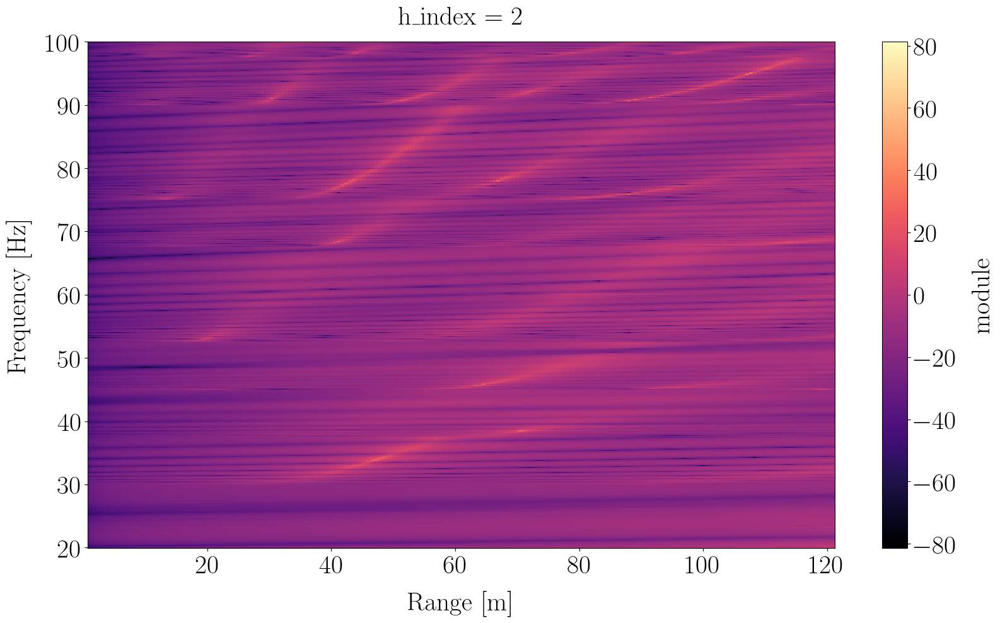

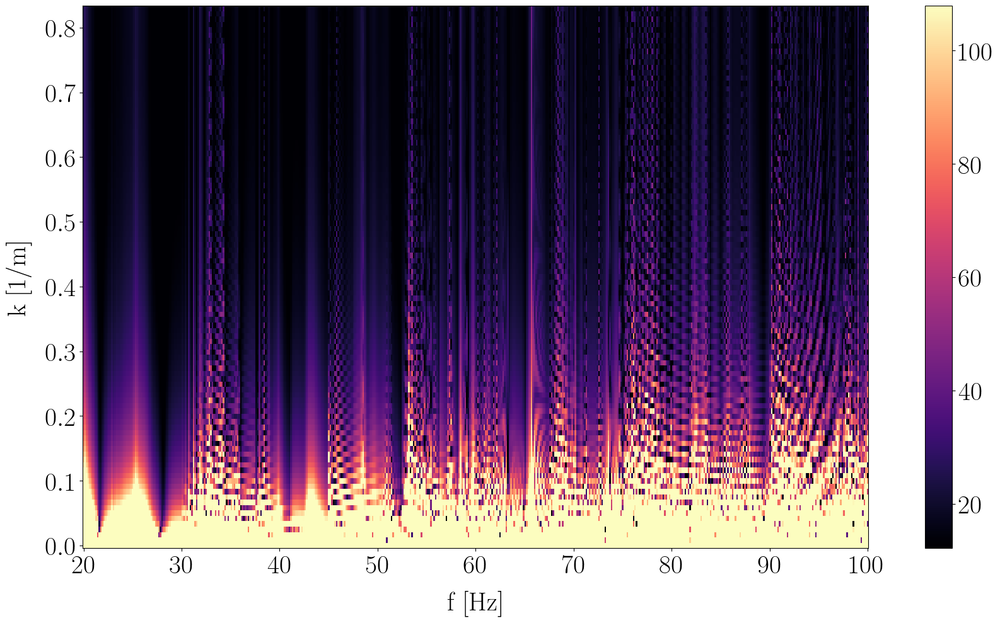

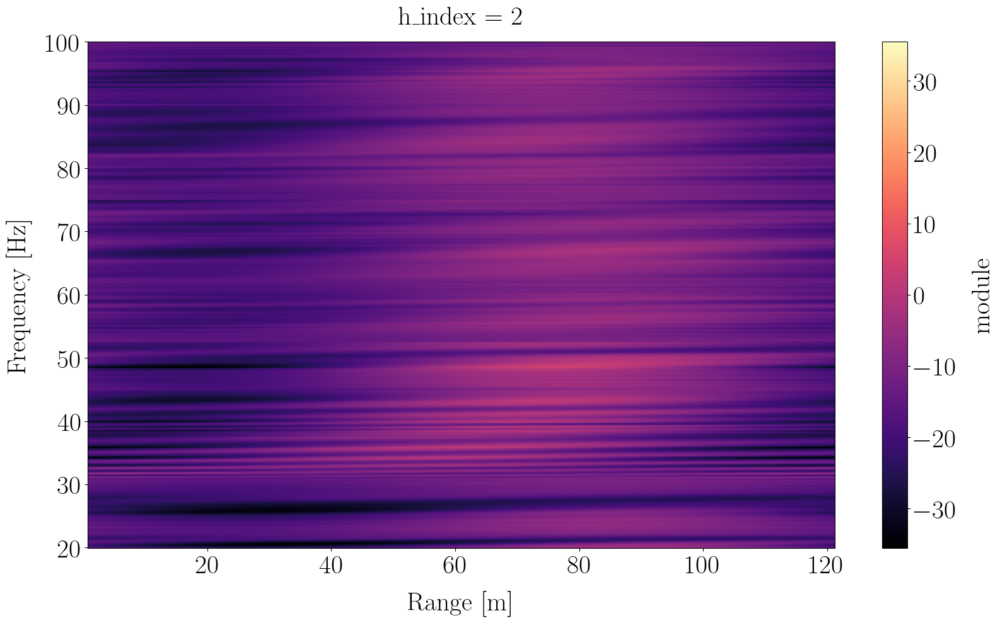

In [18]:
# k_max = 0.005
# lambda_c = 2*np.pi/k_max
# print(f"Lambda min = {lambda_c}")

rtf_mod = ds.module.sel(h_index=2)

smooth_data = np.ones_like(ds.data)
rtf_mod_smooth = rtf_mod.copy().values

for q in range(0, Q):
    I_q_inf = q * n_overlap_I
    I_q_sup = q * n_overlap_I + n_I
    I_q_center = q * n_overlap_I + P # P = n_I // 2
    # print(I_q_inf, I_q_sup)
    # Select I_q
    rtf_I_q = rtf_mod.isel(r=slice(I_q_inf, I_q_sup))
    # Apply filter
    rtf_I_q = 10 * np.log10(rtf_I_q**2)
    # Apply FFT along the r dimension
    rtf_I_q_fft = np.fft.rfft(rtf_I_q, axis=1)
    k = np.fft.rfftfreq(rtf_I_q.shape[1], d=dr)  #

    # Filter desired k
    rtf_I_q_fft_filt = np.copy(rtf_I_q_fft)
    rtf_I_q_fft_filt[:, k > k_max] = 0
    rtf_I_q_filt = np.fft.irfft(rtf_I_q_fft_filt, n=rtf_I_q.shape[1], axis=1)
    rtf_I_q_filt = 10 ** (rtf_I_q_filt / 20)

    if q == 0:
        plt.figure()
        rtf_I_q.plot(x="r", cmap="magma")

        plt.figure()
        vmin = np.percentile(np.abs(rtf_I_q_fft), 10)
        vmax = np.percentile(np.abs(rtf_I_q_fft), 90)
        plt.pcolormesh(
            ds.f.values, k, np.abs(rtf_I_q_fft).T, cmap="magma", vmax=vmax, vmin=vmin
        )
        plt.colorbar()
        plt.xlabel("f [Hz]")
        plt.ylabel("k [1/m]")

        plt.figure()
        rtf_I_q_filt_xr = xr.zeros_like(rtf_I_q)
        rtf_I_q_filt_xr.data = rtf_I_q_filt
        rtf_I_q_filt_plot = 10 * np.log10(rtf_I_q_filt_xr**2)
        rtf_I_q_filt_plot.plot(x="r", cmap="magma")

    # Store modified rtf
    rtf_mod_smooth[:, I_q_center] = rtf_I_q_filt[:, P]
    # rtf_I_q_filt_P = rtf_I_q_filt[:, P]     # Center of the box
    # smooth_rtfs.append(rtf_I_q_filt_P)

# smooth_rtfs = np.array(smooth_rtfs)
# print(smooth_rtfs.shape)

In [19]:
ds_smooth = ds.copy()

rep = np.ones_like(ds.data)
rep[1, ...] = rtf_mod_smooth
ds_smooth.data.data = rep
idx_r_ref = np.argmin(np.abs(ds.r.values - ds.r_ref))
ds_smooth.data_ref.data = rep[:, :, idx_r_ref]

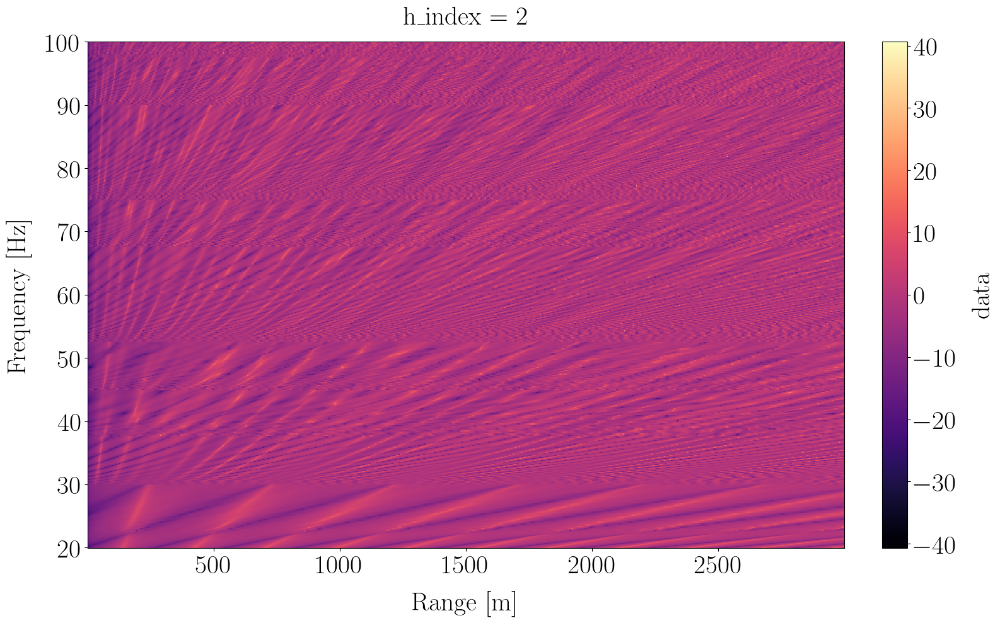

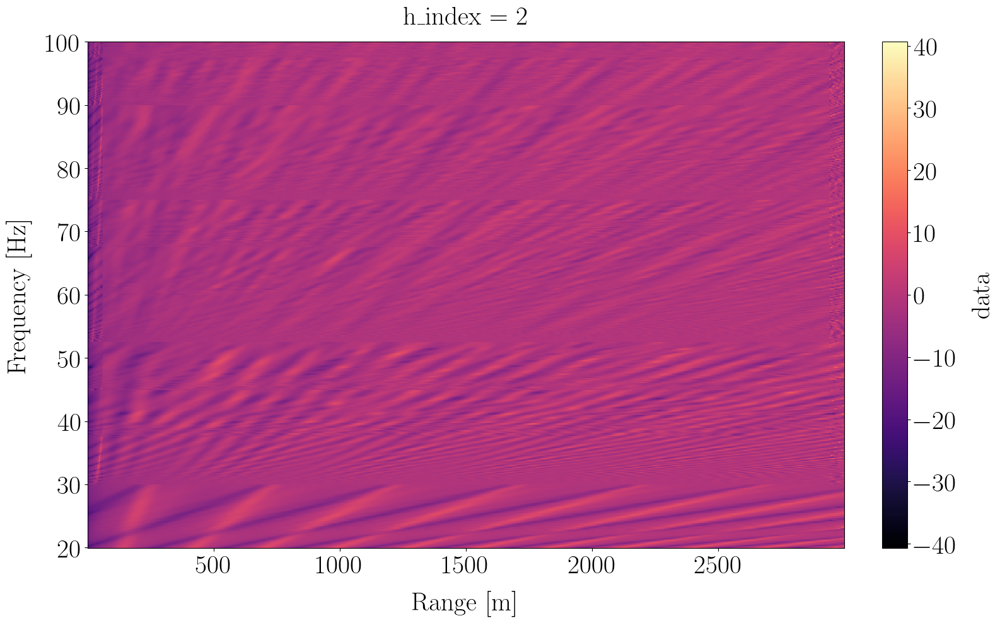

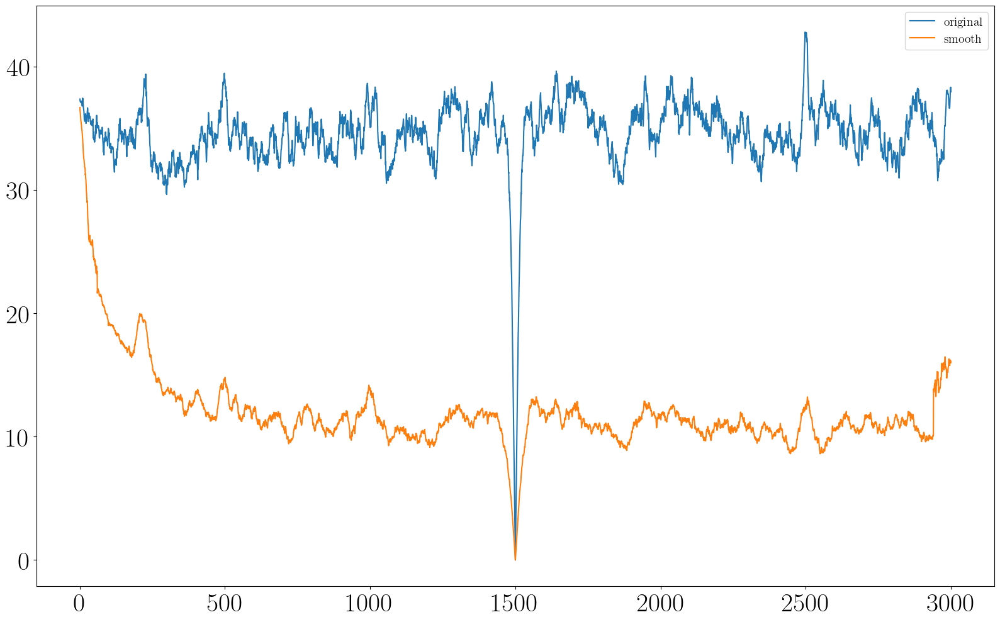

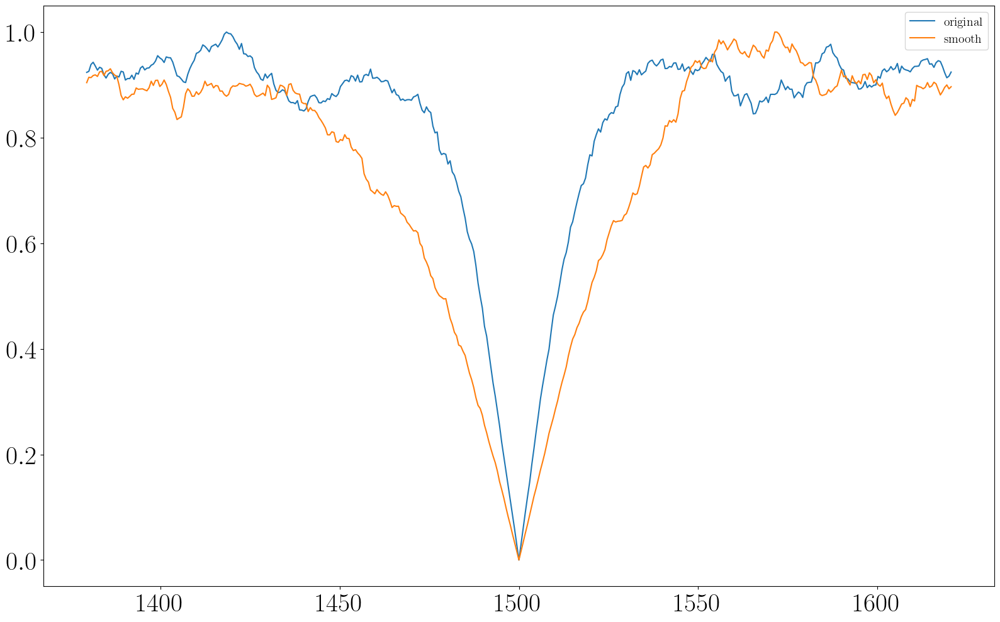

In [20]:
plt.figure()
a = 10 * np.log10(np.abs(ds.data.sel(h_index=2)))
a.plot(x="r", cmap="magma")

plt.figure()
a = 10 * np.log10(np.abs(ds_smooth.data.sel(h_index=2)))
a.plot(x="r", cmap="magma")

dist1 = get_dist(ds, distances=distances)
dist2 = get_dist(ds_smooth, distances=distances)

plt.figure()
plt.plot(ds.r.values, dist1["hermitian_angle"]["d"], label="original")
plt.plot(ds.r.values, dist2["hermitian_angle"]["d"], label="smooth")
plt.legend()

# d1 = (dist1["hermitian_angle"]["d"] - dist1["hermitian_angle"]["d"].min()) /  (dist1["hermitian_angle"]["d"].max() - dist1["hermitian_angle"]["d"].min())
# d2 = (dist2["hermitian_angle"]["d"] - dist2["hermitian_angle"]["d"].min()) /  (dist2["hermitian_angle"]["d"].max() - dist2["hermitian_angle"]["d"].min())
# plt.figure()
# plt.plot(ds.r.values, d1, label="original")
# plt.plot(ds.r.values, d2, label="smooth")
# plt.legend()

# Zoom on main lobe
r_offset = size_I_r
zoom_inf = np.argmin(np.abs(ds.r.values - (ds.r_ref - r_offset)))
zoom_sup = np.argmin(np.abs(ds.r.values - (ds.r_ref + r_offset)))
d1_zoom = dist1["hermitian_angle"]["d"][zoom_inf : zoom_sup + 1]
d2_zoom = dist2["hermitian_angle"]["d"][zoom_inf : zoom_sup + 1]
r_zoom = ds.r.values[zoom_inf : zoom_sup + 1]
d1_zoom = (d1_zoom - d1_zoom.min()) / (d1_zoom.max() - d1_zoom.min())
d2_zoom = (d2_zoom - d2_zoom.min()) / (d2_zoom.max() - d2_zoom.min())
plt.figure()
plt.plot(r_zoom, d1_zoom, label="original")
plt.plot(r_zoom, d2_zoom, label="smooth")
plt.legend()



# plt.xlim([ds.r_ref - 150, ds.r_ref + 150])

C'est un peu mieux, pas miraculeux, mais on peut légèrement élargir le lobe principal au prix du contraste. 

Le problème est a priori de bien choisir la taille des fenêtres et le nombre d'onde de coupure $k_c$ du filtre passe bas à appliquer. 


#### Seuil défini en fonction du percentile d'énergie dans chaque bande 

Dans le cas où la période d'échantillonnage spatial est inconnue on doit définir le seuil $k_c$ automatiquement.  

Pour chaque bin fréquentiel, on définit le seuil en fonction d'un percentile $q$ donné de la distribution d'énergie. 

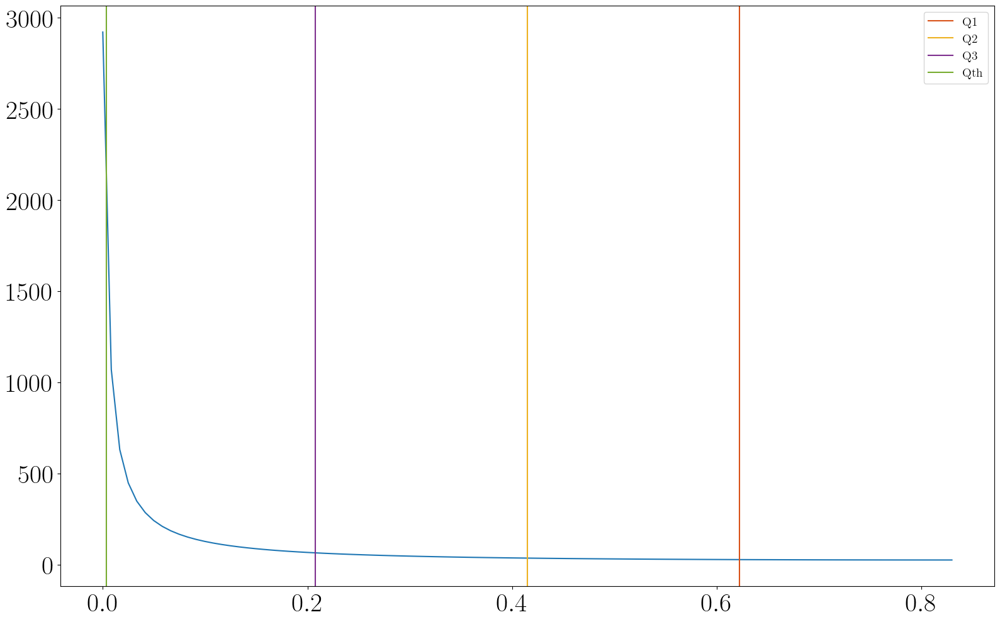

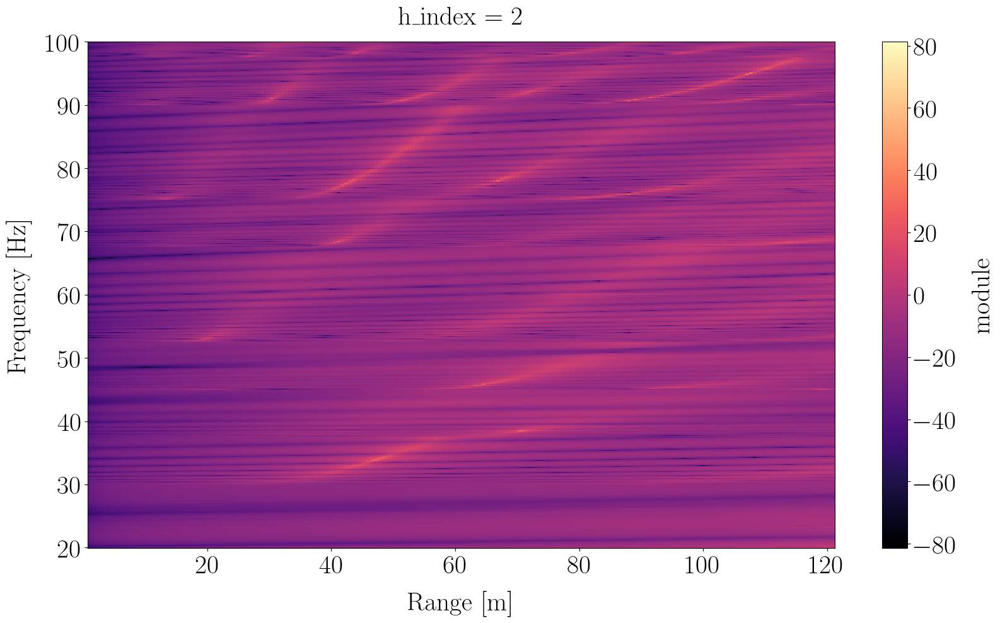

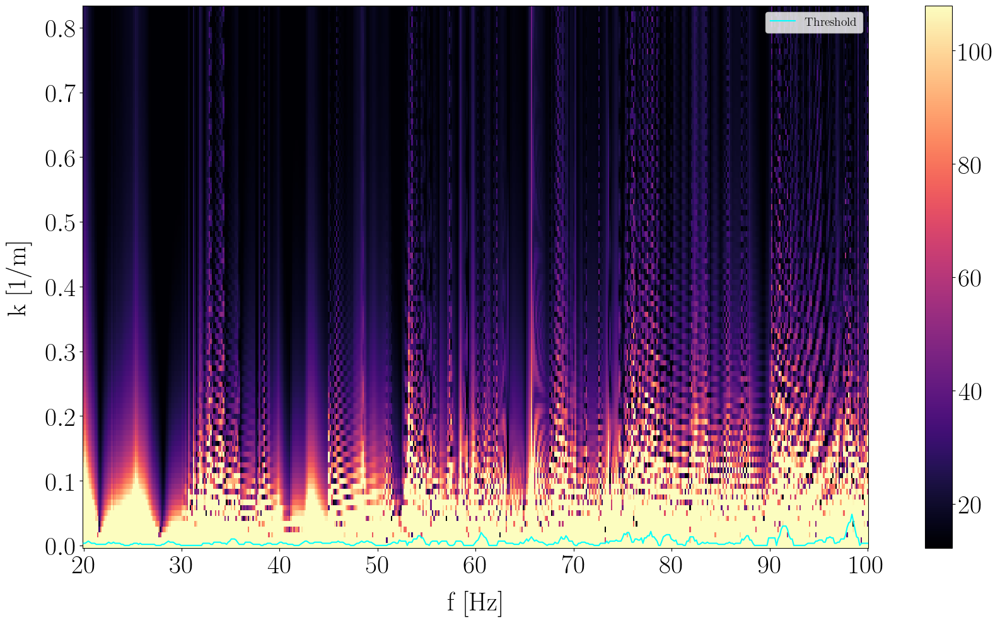

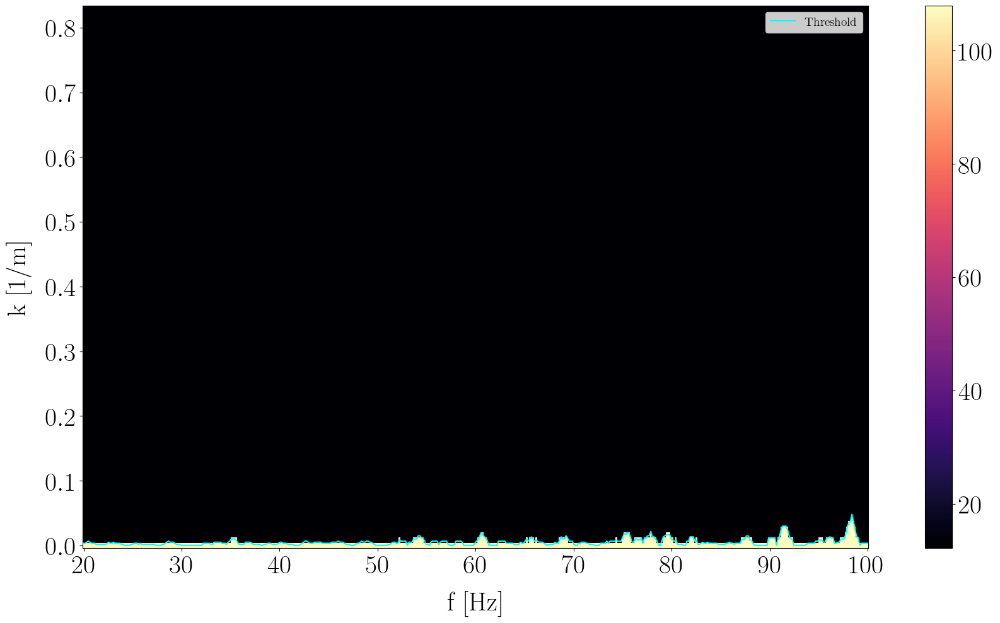

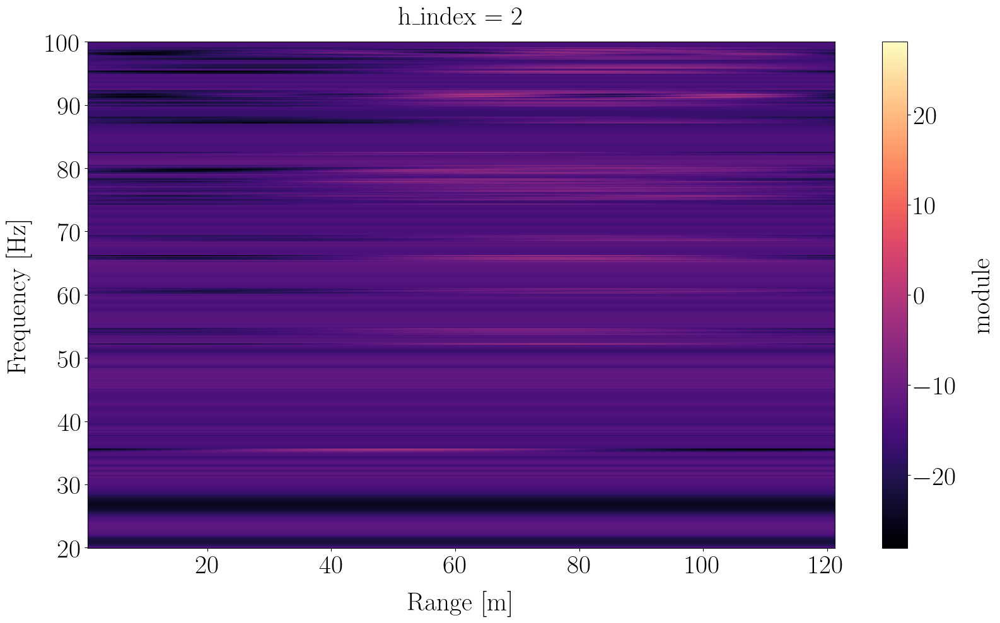

In [21]:
f = ds.f.values 
qth = 99.5
# Visualize the energy distribution
rtf_mod = ds.module.sel(h_index=2)

smooth_data = np.ones_like(ds.data)
rtf_mod_smooth = rtf_mod.copy().values

for q in range(0, Q):
    I_q_inf = q * n_overlap_I
    I_q_sup = q * n_overlap_I + n_I
    I_q_center = q * n_overlap_I + P  # P = n_I // 2
    # print(I_q_inf, I_q_sup)
    # Select I_q
    rtf_I_q = rtf_mod.isel(r=slice(I_q_inf, I_q_sup))
    # Apply filter
    rtf_I_q = 10 * np.log10(rtf_I_q**2)
    # Apply FFT along the r dimension
    rtf_I_q_fft = np.fft.rfft(rtf_I_q, axis=1)
    rtf_I_q_psd = np.abs(rtf_I_q_fft)

    k = np.fft.rfftfreq(rtf_I_q.shape[1], d=dr)  #

    # Extract quantiles of the distribution and their corresponding x values
    q_th = np.percentile(rtf_I_q_psd, qth, axis=1)

    # # Get abcisse corresponding to the quantiles : x_q1, mu(x_q1) = q1, x_q2, mu(x_q2) = q2, x_q3, mu(x_q3) = q3
    dx_qth = np.abs(rtf_I_q_psd - q_th[:, np.newaxis])  #
    idx_xqth = np.argmin(dx_qth, axis=1)
    x_qth = k[idx_xqth]
    # print(x_qth)

    # Smooth with rolling average to avoid abrupt changes betweens adjacent bins
    n_roll_avg = 5
    x_qth = np.convolve(x_qth, np.ones(n_roll_avg) / n_roll_avg, mode="same")

    # Filter desired k
    rtf_I_q_fft_filt = np.copy(rtf_I_q_fft)     # nf, nk
    # Define dedicated mask
    kk, ff = np.meshgrid(k, f)
    mask_fk = kk > x_qth[:, np.newaxis]
    # Apply mask
    rtf_I_q_fft_filt[mask_fk] = 0
    rtf_I_q_filt = np.fft.irfft(rtf_I_q_fft_filt, n=rtf_I_q.shape[1], axis=1)
    rtf_I_q_filt = 10 ** (rtf_I_q_filt / 20)

    if q == 0:
        q1 = np.percentile(rtf_I_q_psd, 25, axis=1)
        q2 = np.percentile(rtf_I_q_psd, 50, axis=1)
        q3 = np.percentile(rtf_I_q_psd, 75, axis=1)

        # Q1
        dx_q1 = np.abs(rtf_I_q_psd - q1[:, np.newaxis])  #
        idx_xq1 = np.argmin(dx_q1, axis=1)
        x_q1 = k[idx_xq1]
        # Q2
        dx_q2 = np.abs(rtf_I_q_psd - q2[:, np.newaxis])
        idx_xq2 = np.argmin(dx_q2, axis=1)
        x_q2 = k[idx_xq2]
        # Q3
        dx_q3 = np.abs(rtf_I_q_psd - q3[:, np.newaxis])
        idx_xq3 = np.argmin(dx_q3, axis=1)
        x_q3 = k[idx_xq3]

        plt.figure()
        plt.plot(k, rtf_I_q_psd[0, :])
        plt.axvline(x_q1[0], color=color(1), label="Q1")
        plt.axvline(x_q2[0], color=color(2), label="Q2")
        plt.axvline(x_q3[0], color=color(3), label="Q3")
        plt.axvline(x_qth[0], color=color(4), label="Qth")
        plt.legend()

        plt.figure()
        rtf_I_q.plot(x="r", cmap="magma")

        plt.figure()
        vmin = np.percentile(rtf_I_q_psd, 10)
        vmax = np.percentile(rtf_I_q_psd, 90)
        plt.pcolormesh(f, k, rtf_I_q_psd.T, cmap="magma", vmax=vmax, vmin=vmin)
        plt.plot(f, x_qth, color="cyan", label="Threshold", zorder=10)
        plt.colorbar()
        plt.xlabel("f [Hz]")
        plt.ylabel("k [1/m]")
        plt.legend()

        plt.figure()
        rtf_I_q_fft_filt_psd = np.abs(rtf_I_q_fft_filt)**2
        vmin = np.percentile(rtf_I_q_psd, 10)
        vmax = np.percentile(rtf_I_q_psd, 90)
        plt.pcolormesh(
            f, k, np.abs(rtf_I_q_fft_filt_psd).T, cmap="magma", vmax=vmax, vmin=vmin
        )
        plt.plot(f, x_qth, color="cyan", label="Threshold", zorder=10)
        plt.colorbar()
        plt.xlabel("f [Hz]")
        plt.ylabel("k [1/m]")
        plt.legend()

        plt.figure()
        rtf_I_q_filt_xr = xr.zeros_like(rtf_I_q)
        rtf_I_q_filt_xr.data = rtf_I_q_filt
        rtf_I_q_filt_plot = 10 * np.log10(rtf_I_q_filt_xr**2)
        rtf_I_q_filt_plot.plot(x="r", cmap="magma")

        # print(I_q_center)

    # Store modified rtf
    rtf_mod_smooth[:, I_q_center] = rtf_I_q_filt[:, P]
    # rtf_I_q_filt_P = rtf_I_q_filt[:, P]     # Center of the box
    # smooth_rtfs.append(rtf_I_q_filt_P)

# smooth_rtfs = np.array(smooth_rtfs)
# print(smooth_rtfs.shape)

In [22]:
ds_smooth = ds.copy()

rep = np.ones_like(ds.data)
rep[1, ...] = rtf_mod_smooth
ds_smooth.data.data = rep
idx_r_ref = np.argmin(np.abs(ds.r.values - ds.r_ref))
ds_smooth.data_ref.data = rep[:, :, idx_r_ref]

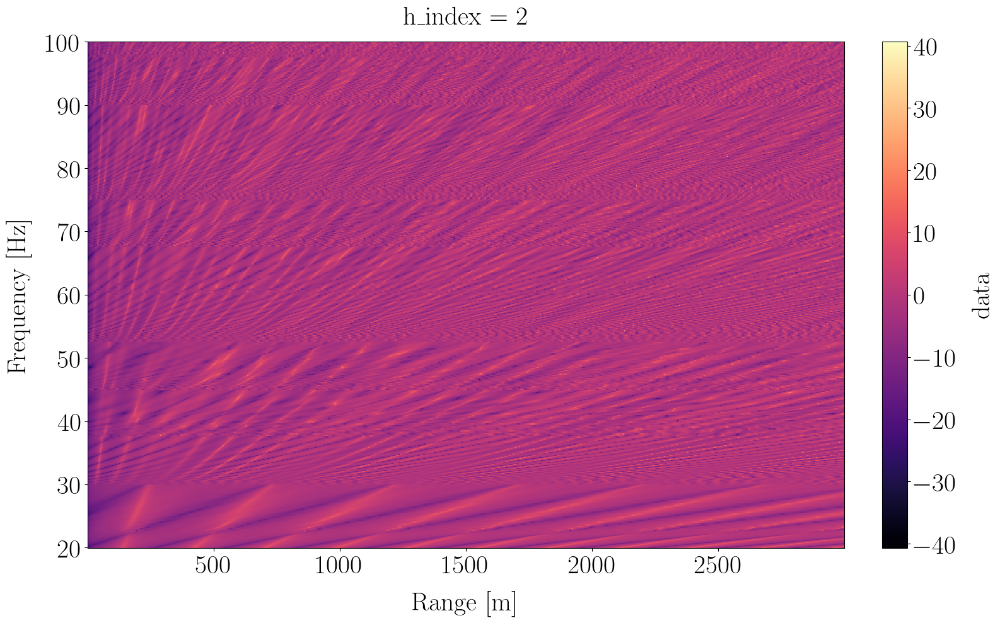

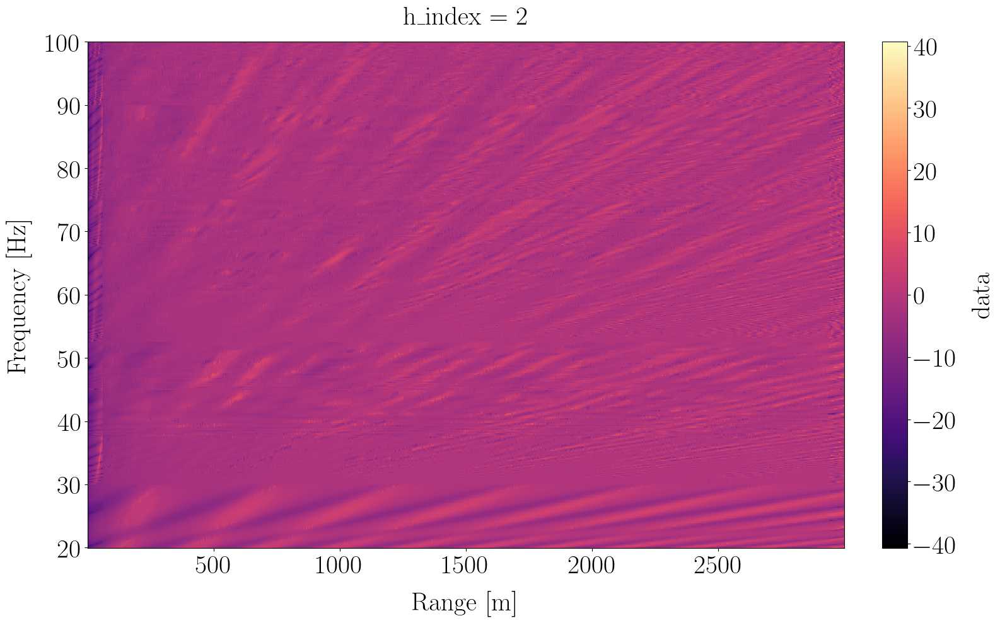

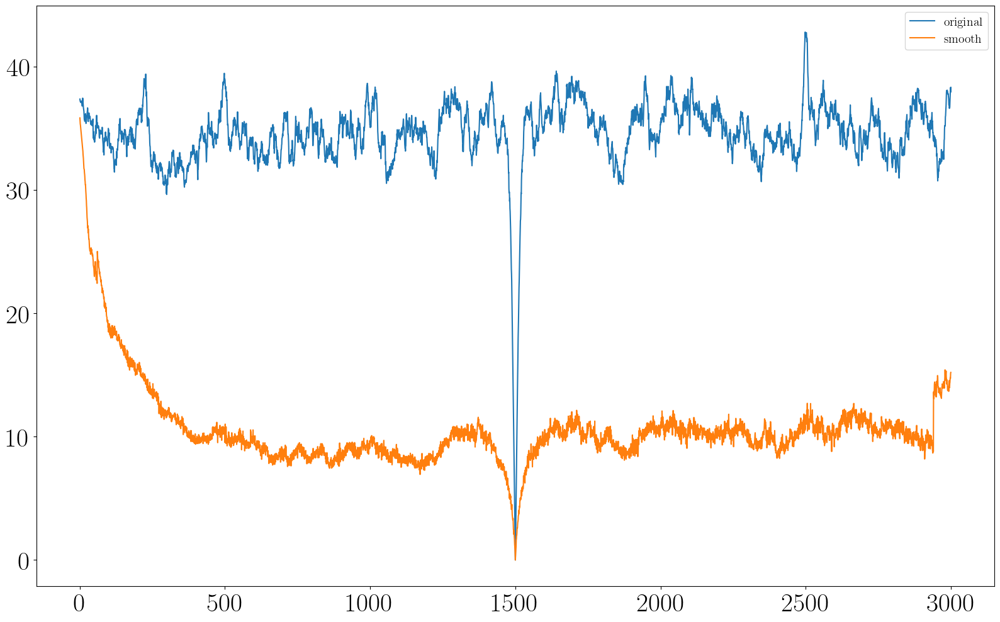

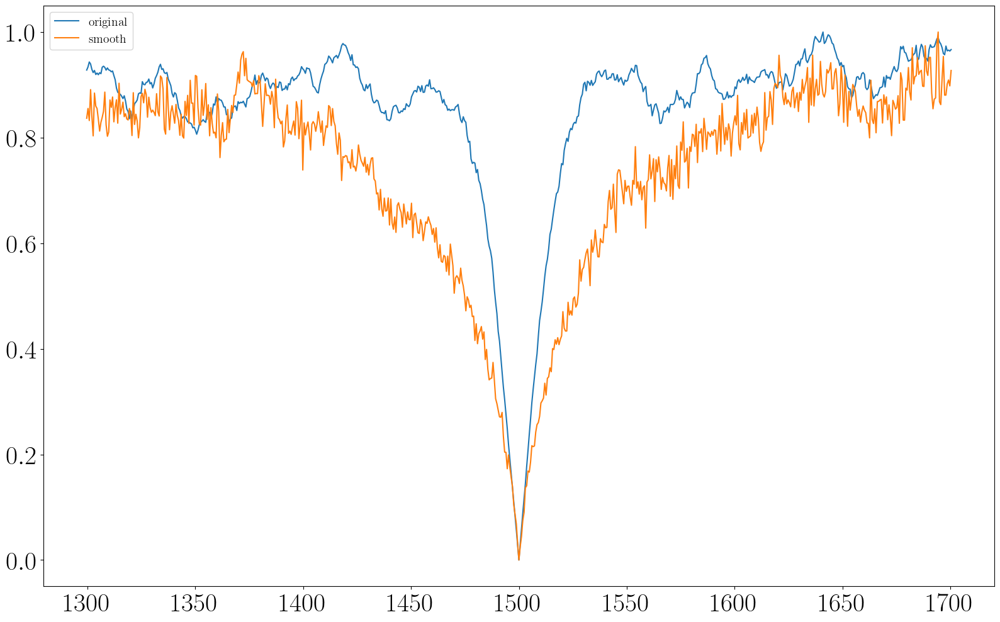

In [23]:
plt.figure()
a = 10 * np.log10(np.abs(ds.data.sel(h_index=2)))
a.plot(x="r", cmap="magma")

plt.figure()
a = 10 * np.log10(np.abs(ds_smooth.data.sel(h_index=2)))
a.plot(x="r", cmap="magma")

dist1 = get_dist(ds, distances=distances)
dist2 = get_dist(ds_smooth, distances=distances)

plt.figure()
plt.plot(ds.r.values, dist1["hermitian_angle"]["d"], label="original")
plt.plot(ds.r.values, dist2["hermitian_angle"]["d"], label="smooth")
plt.legend()

# # Remove first and last points out of windows
# I_q_center_first = 0 * n_overlap_I + P  # P = n_I // 2
# I_q_center_last = (Q-1) * n_overlap_I + P  # P = n_I // 2
# # print(I_q_center_first, I_q_center_last)

# d1 = dist1["hermitian_angle"]["d"][I_q_center_first : I_q_center_last + 1]
# d2 = dist2["hermitian_angle"]["d"][I_q_center_first : I_q_center_last + 1]
# r_valid = ds.r.values[I_q_center_first : I_q_center_last + 1]
# d1 = (d1 - d1.min()) / (d1.max() - d1.min())
# d2 = (d2 - d2.min()) / (d2.max() - d2.min())
# plt.figure()
# plt.plot(r_valid, d1, label="original")
# plt.plot(r_valid, d2, label="smooth")
# plt.legend()


# Zoom on main lobe
r_offset = 200
zoom_inf = np.argmin(np.abs(ds.r.values - (ds.r_ref - r_offset)))
zoom_sup = np.argmin(np.abs(ds.r.values - (ds.r_ref + r_offset)))
d1_zoom = dist1["hermitian_angle"]["d"][zoom_inf : zoom_sup + 1]
d2_zoom = dist2["hermitian_angle"]["d"][zoom_inf : zoom_sup + 1]
r_zoom = ds.r.values[zoom_inf : zoom_sup + 1]
d1_zoom = (d1_zoom - d1_zoom.min()) / (d1_zoom.max() - d1_zoom.min())
d2_zoom = (d2_zoom - d2_zoom.min()) / (d2_zoom.max() - d2_zoom.min())
plt.figure()
plt.plot(r_zoom, d1_zoom, label="original")
plt.plot(r_zoom, d2_zoom, label="smooth")
plt.legend()


# plt.xlim([ds.r_ref - 150, ds.r_ref + 150])

# # debug : Check first is ok
# plt.figure()
# a = 10 * np.log10(np.abs(ds_smooth.data.sel(h_index=2)))
# a.plot(x="r", cmap="magma")
# plt.xlim([ds.r.values[I_q_center_first - 10], ds.r.values[I_q_center_first + 10]])

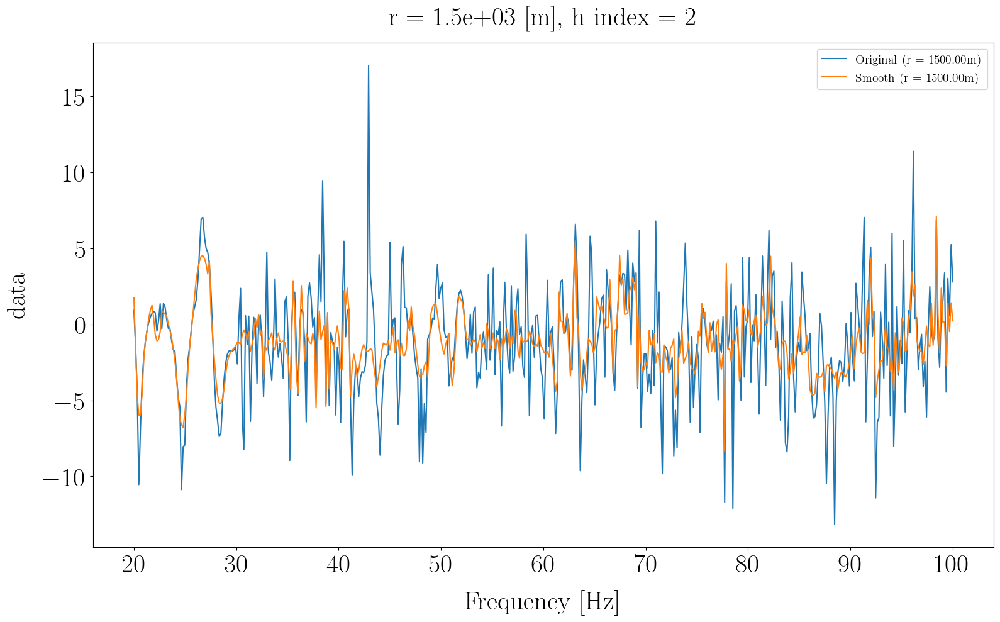

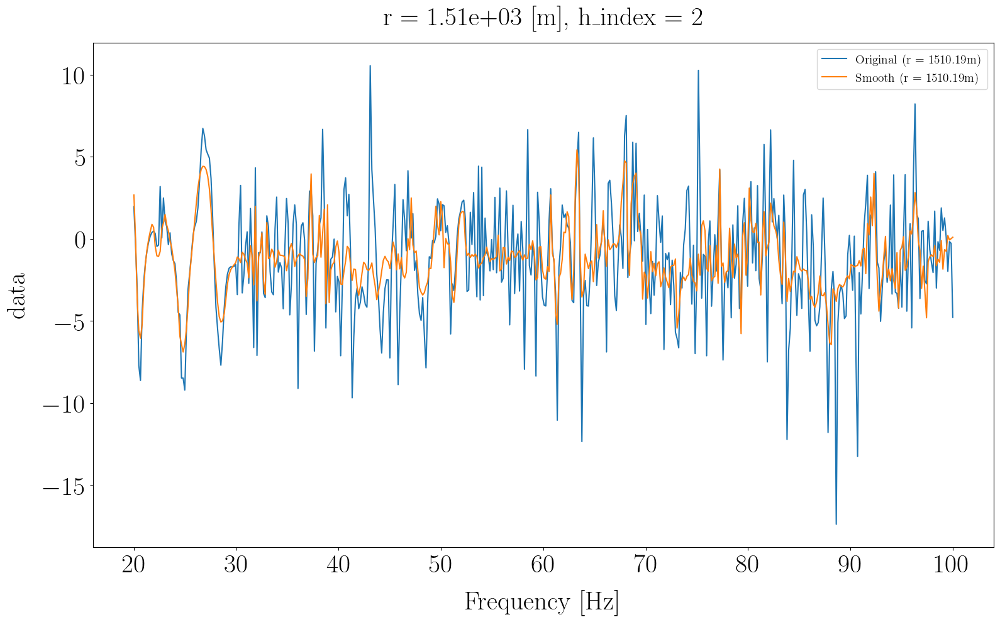

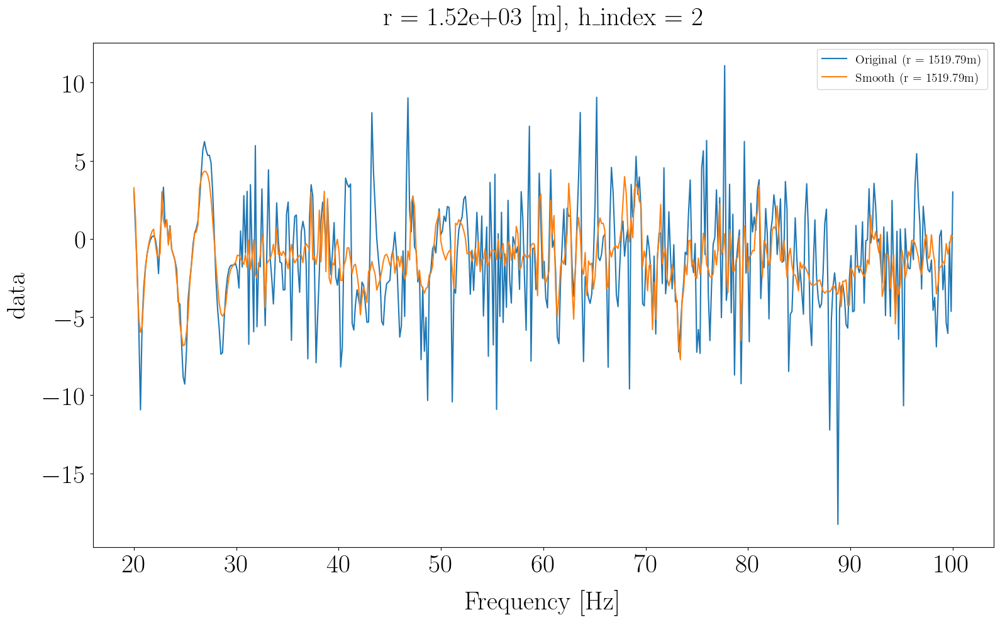

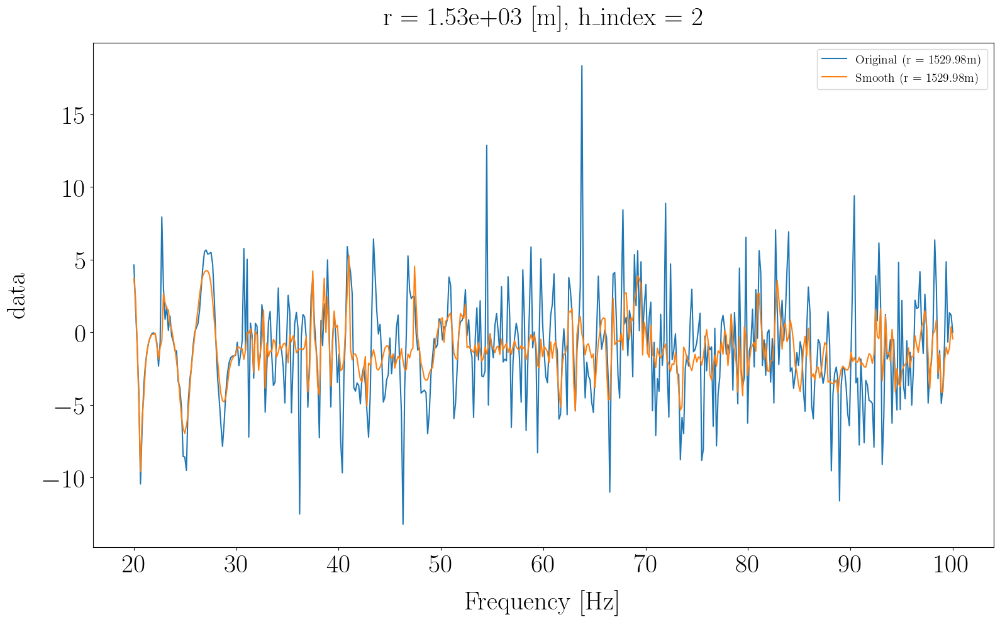

In [24]:
before_smooth = 10 * np.log10(np.abs(ds.data.sel(h_index=2)))
after_smooth = 10 * np.log10(np.abs(ds_smooth.data.sel(h_index=2)))

sel_ranges = [ds.r_ref, ds.r_ref+10, ds.r_ref+20, ds.r_ref+30]
for i_rs, rs in enumerate(sel_ranges):
    before_smooth_rs = before_smooth.sel(r=rs, method="nearest")
    after_smooth_rs = after_smooth.sel(r=rs, method="nearest")

    plt.figure()
    before_smooth_rs.plot(x="f", label=f"Original (r = {before_smooth_rs.r.values:.2f}m)")
    after_smooth_rs.plot(x="f", label=f"Smooth (r = {after_smooth_rs.r.values:.2f}m)")
    # plt.xscale("log")
    plt.legend()

Avec cette approche, les structures de RTF préservée sont les structures qui évoluent lentement en espace. Un pic marqué dans un rapport de fonction de transfert, mais qui n'est visible que sur quelques mètres n'a pas d'intérêt pour la localisation et dégrade les performances. 

### Choix de la taille des fenêtres 


**Condition sur la taille de la fenêtre**

La résolution du spectre calculé (i.e RTF transformée dans le plan f, k) dépend du choix de la taille de la fenêtre glissante. La résolution en nombre d'onde $\Delta k$ est donnée par : 

$$ \Delta k = \frac{1}{n_I \Delta r } $$

où $n_I = 2P + 1 $ est la taille des fenêtres $I_q$ utilisées.

En particulier, le plus petit $k$ non nul observable noté $k_1$, c'est à dire, est donné par : 

$$ k_1 = \Delta k = \frac{1}{n_I \Delta r }$$

Si l'on choisit un seuil $k_{c}$ pour le filtre tel que $0 <k_{c} < k_1$, alors :

$$ \forall k, k \neq 0, k > k_{c} $$

et donc toute les longeurs d'onde différentes de $ + \infty$ (composante continue $k = 0$) sont filtrées.  

Dit autrement, la plus grande longueur d'onde que l'on peut garder après filtrage est donnée par :

$$ \lambda_{max}  = \frac{2\pi}{k_1} = 2 \pi n_I \Delta r$$

C'est vrai ce que je raconte ?? 

**Influence sur le filtrage**

A COMPLÉTER 
<!-- Les plus petits nombre d'onde  -->


# Test sur un guide d'onde plus représentatif de Groix 

In [25]:
# Parameters
bottom_bc="perfectly_rigid"
waveguide_depth=30
d_inter_rcv=1000
z_rcv=29
src_ref_range=1.5 * 1e3
z_src=5
nrgrid=5001
delta_r=1 * 1e3
fmin=200
fmax=800
nfgrid=500

In [26]:
distances=["hermitian_angle"]

ds = run_full_study(
    bottom_bc=bottom_bc,
    waveguide_depth=waveguide_depth,
    d_inter_rcv=d_inter_rcv,
    z_rcv=z_rcv,
    src_ref_range=src_ref_range,
    z_src=z_src,
    nrgrid=nrgrid,
    delta_r=delta_r,
    fmin=fmin,
    fmax=fmax,
    nfgrid=nfgrid,
    root_img=sensibility_img_folder,
    distances=distances,
    n_modes=None,
)

Number of propagating modes at fmin = 200 Hz : 8
Number of propagating modes at fmax = 800 Hz : 32
Dataset computed


In [27]:
# Range step
dr = ds.r.values[1] - ds.r.values[0]
n_r = ds.r.size

# Define the size of the Iq windows
P = 100
n_overlap_I = 1
n_I = 2 * P + 1
size_I_r = n_I * dr

print(
    f"Selected window I size:  n_I = {n_I} samples (equivalent to L_I = {size_I_r:.1f}m)"
)

# Compute the number of I_q windows Q
Q = int(np.floor((n_r + n_overlap_I - n_I)/n_overlap_I))
print(f"Number of available segments I : Q = {Q}")

Selected window I size:  n_I = 201 samples (equivalent to L_I = 80.4m)
Number of available segments I : Q = 4801


In [28]:
# k_max = 0.005

k_win = 2 * np.pi / size_I_r    # k for lambda = L_I
k_max = k_win / 6       # Lambda min = 8 * L_I
print(f"k_c = {k_max}")
lambda_c = 2 * np.pi / k_max
print(f"Lambda min = {lambda_c:.2f}m")

print(f"delta_k resolution = {1 / size_I_r:.5f} m^-1")

k_c = 0.013024845164137528
Lambda min = 482.40m
delta_k resolution = 0.01244 m^-1


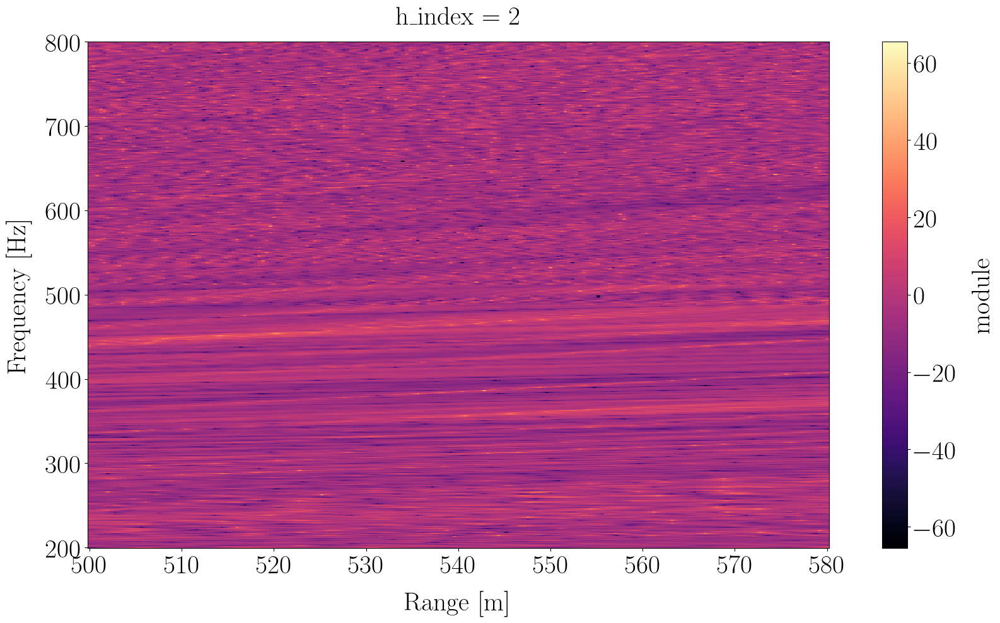

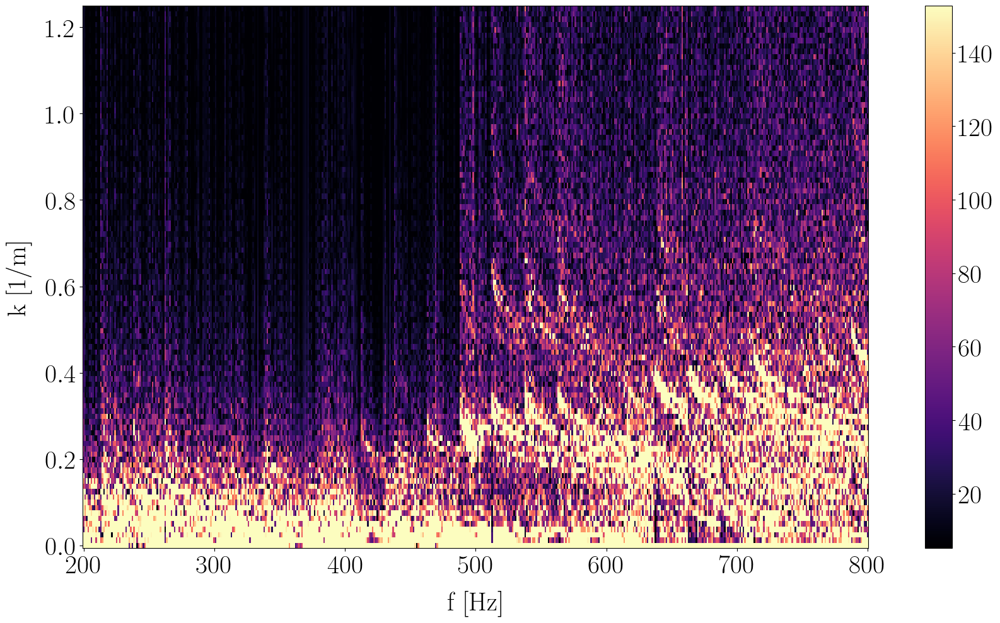

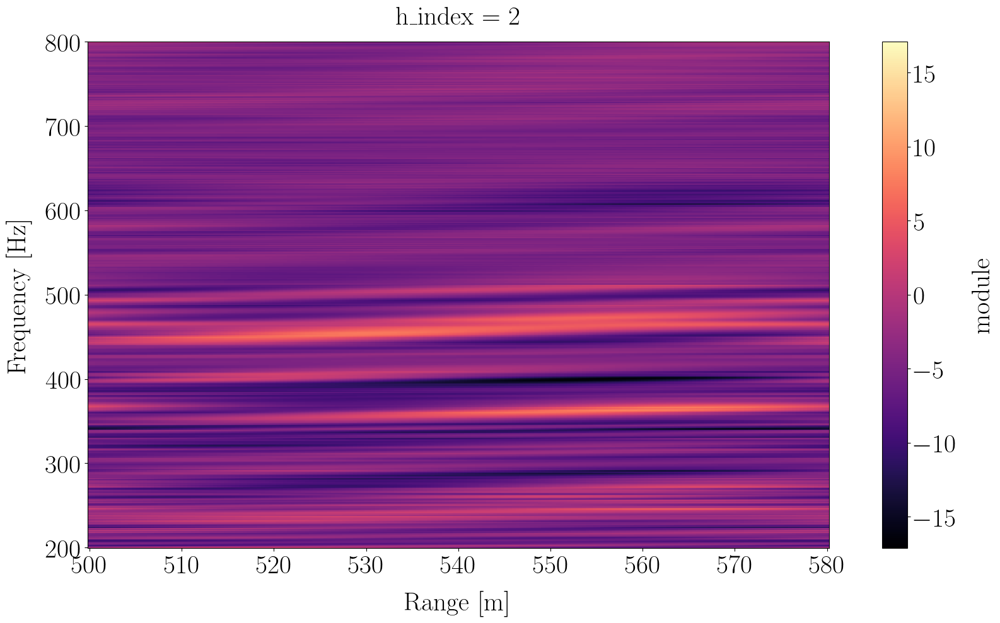

In [29]:
rtf_mod = ds.module.sel(h_index=2)

smooth_data = np.ones_like(ds.data)
rtf_mod_smooth = rtf_mod.copy().values

for q in range(0, Q):
    I_q_inf = q * n_overlap_I
    I_q_sup = q * n_overlap_I + n_I
    I_q_center = q * n_overlap_I + P # P = n_I // 2
    # print(I_q_inf, I_q_sup)
    # Select I_q
    rtf_I_q = rtf_mod.isel(r=slice(I_q_inf, I_q_sup))
    # Apply filter
    rtf_I_q = 10 * np.log10(rtf_I_q**2)
    # Apply FFT along the r dimension
    rtf_I_q_fft = np.fft.rfft(rtf_I_q, axis=1)
    k = np.fft.rfftfreq(rtf_I_q.shape[1], d=dr)  #

    # Filter desired k
    rtf_I_q_fft_filt = np.copy(rtf_I_q_fft)
    rtf_I_q_fft_filt[:, k > k_max] = 0
    rtf_I_q_filt = np.fft.irfft(rtf_I_q_fft_filt, n=rtf_I_q.shape[1], axis=1)
    rtf_I_q_filt = 10 ** (rtf_I_q_filt / 20)

    if q == 0:
        plt.figure()
        rtf_I_q.plot(x="r", cmap="magma")

        plt.figure()
        vmin = np.percentile(np.abs(rtf_I_q_fft), 10)
        vmax = np.percentile(np.abs(rtf_I_q_fft), 90)
        plt.pcolormesh(
            ds.f.values, k, np.abs(rtf_I_q_fft).T, cmap="magma", vmax=vmax, vmin=vmin
        )
        plt.colorbar()
        plt.xlabel("f [Hz]")
        plt.ylabel("k [1/m]")

        plt.figure()
        rtf_I_q_filt_xr = xr.zeros_like(rtf_I_q)
        rtf_I_q_filt_xr.data = rtf_I_q_filt
        rtf_I_q_filt_plot = 10 * np.log10(rtf_I_q_filt_xr**2)
        rtf_I_q_filt_plot.plot(x="r", cmap="magma")

    # Store modified rtf
    rtf_mod_smooth[:, I_q_center] = rtf_I_q_filt[:, P]
    # rtf_I_q_filt_P = rtf_I_q_filt[:, P]     # Center of the box
    # smooth_rtfs.append(rtf_I_q_filt_P)

# smooth_rtfs = np.array(smooth_rtfs)
# print(smooth_rtfs.shape)

In [30]:
ds_smooth = ds.copy()

rep = np.ones_like(ds.data)
rep[1, ...] = rtf_mod_smooth
ds_smooth.data.data = rep
idx_r_ref = np.argmin(np.abs(ds.r.values - ds.r_ref))
ds_smooth.data_ref.data = rep[:, :, idx_r_ref]

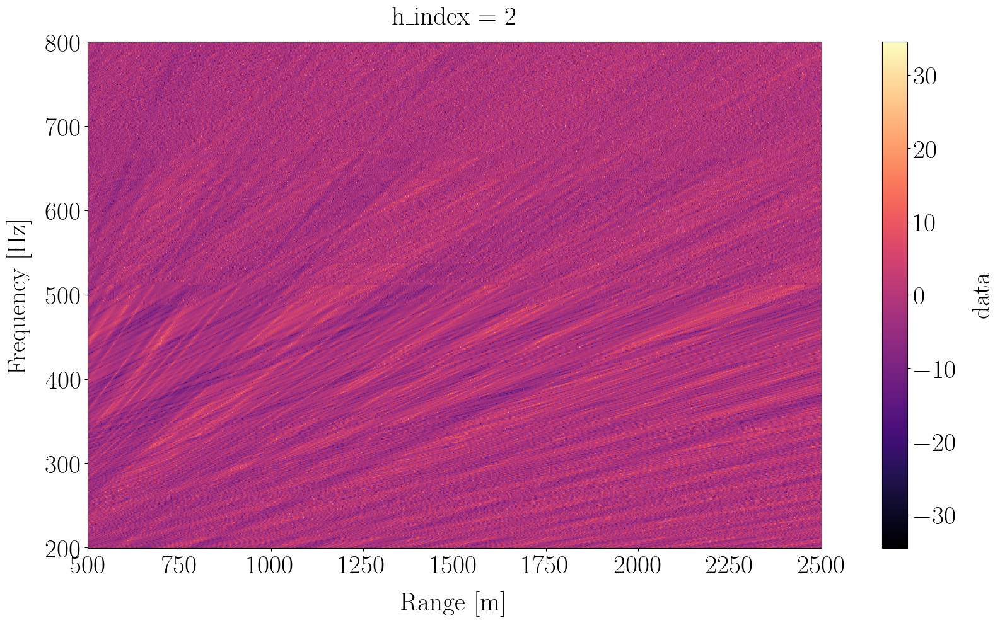

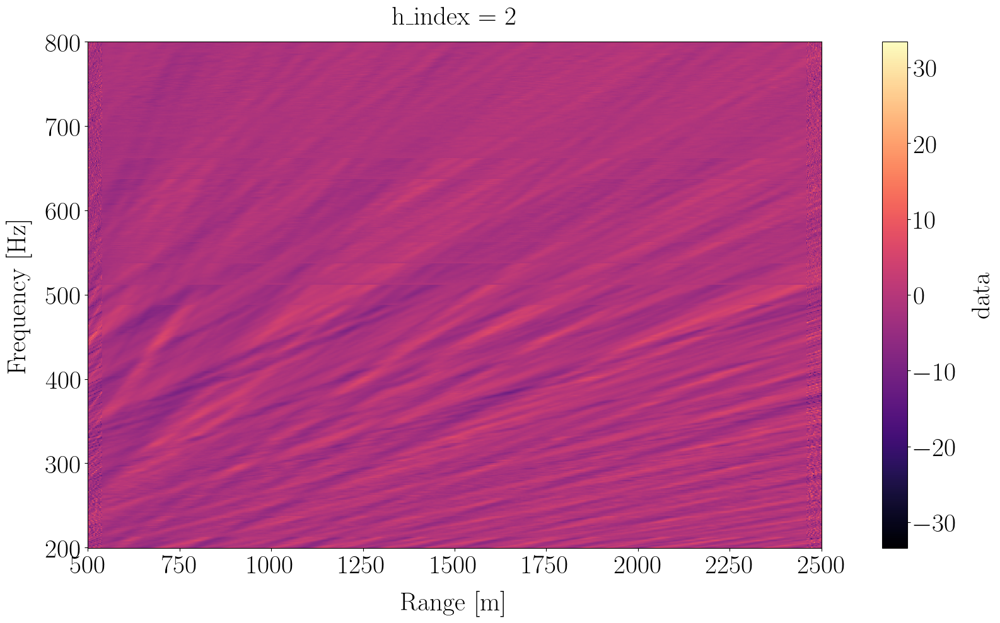

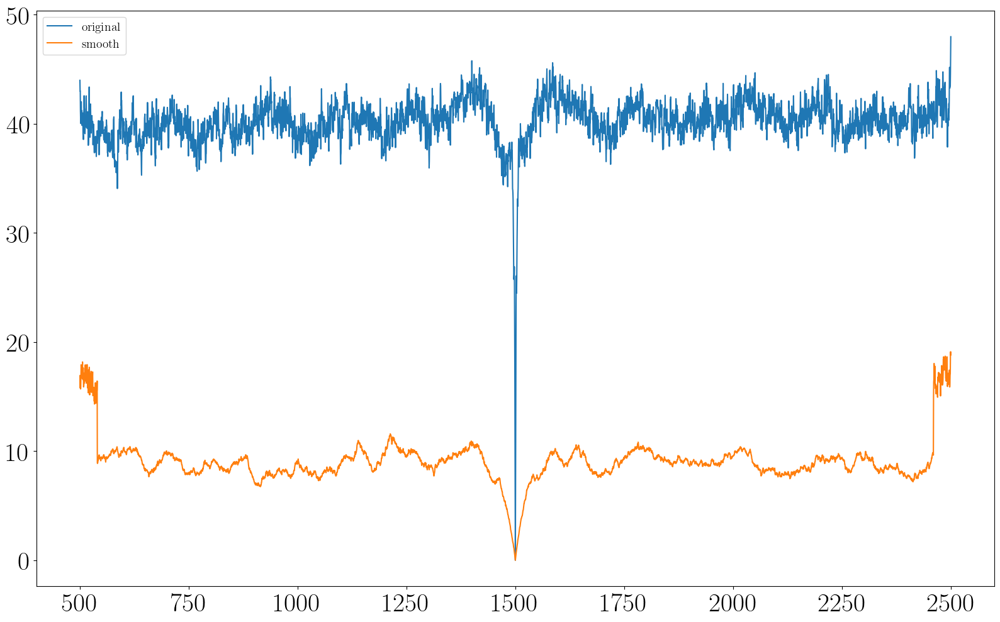

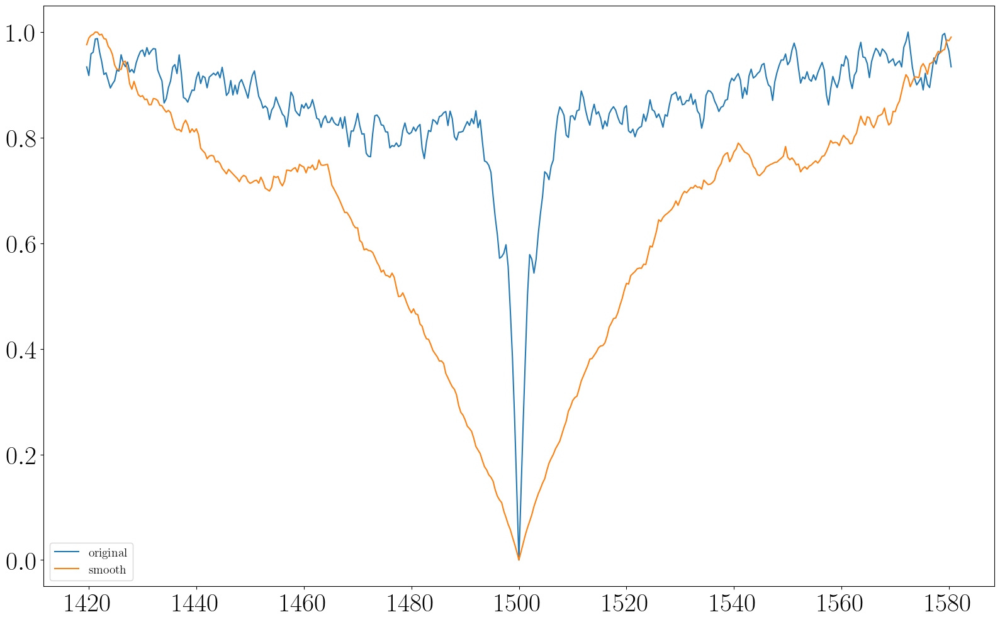

In [31]:
plt.figure()
a = 10 * np.log10(np.abs(ds.data.sel(h_index=2)))
a.plot(x="r", cmap="magma")

plt.figure()
a = 10 * np.log10(np.abs(ds_smooth.data.sel(h_index=2)))
a.plot(x="r", cmap="magma")

dist1 = get_dist(ds, distances=distances)
dist2 = get_dist(ds_smooth, distances=distances)

plt.figure()
plt.plot(ds.r.values, dist1["hermitian_angle"]["d"], label="original")
plt.plot(ds.r.values, dist2["hermitian_angle"]["d"], label="smooth")
plt.legend()

# d1 = (dist1["hermitian_angle"]["d"] - dist1["hermitian_angle"]["d"].min()) /  (dist1["hermitian_angle"]["d"].max() - dist1["hermitian_angle"]["d"].min())
# d2 = (dist2["hermitian_angle"]["d"] - dist2["hermitian_angle"]["d"].min()) /  (dist2["hermitian_angle"]["d"].max() - dist2["hermitian_angle"]["d"].min())
# plt.figure()
# plt.plot(ds.r.values, d1, label="original")
# plt.plot(ds.r.values, d2, label="smooth")
# plt.legend()

# Zoom on main lobe
r_offset = size_I_r
zoom_inf = np.argmin(np.abs(ds.r.values - (ds.r_ref - r_offset)))
zoom_sup = np.argmin(np.abs(ds.r.values - (ds.r_ref + r_offset)))
d1_zoom = dist1["hermitian_angle"]["d"][zoom_inf : zoom_sup + 1]
d2_zoom = dist2["hermitian_angle"]["d"][zoom_inf : zoom_sup + 1]
r_zoom = ds.r.values[zoom_inf : zoom_sup + 1]
d1_zoom = (d1_zoom - d1_zoom.min()) / (d1_zoom.max() - d1_zoom.min())
d2_zoom = (d2_zoom - d2_zoom.min()) / (d2_zoom.max() - d2_zoom.min())
plt.figure()
plt.plot(r_zoom, d1_zoom, label="original")
plt.plot(r_zoom, d2_zoom, label="smooth")
plt.legend()



# plt.xlim([ds.r_ref - 150, ds.r_ref + 150])

In [32]:
def plot_dist_ref_pos(ds_rtf, r_dist, dist):
    # Extract r around r_ref
    r = r_dist
    r_minus_rref = r - ds_rtf.r_ref
    dr_pos_idx = r_minus_rref >= 0
    r_pos = r[dr_pos_idx]

    # Plot module and phase at close pos
    for i, d_type in enumerate(dist.keys()):

        # theta_thresholds = [20, 30, 40]
        # Get dist
        d = dist[d_type]["d"]
        d_name = dist[d_type]["name"]
        d_unit = dist[d_type]["unit"]

        if d_unit == "-":
            d_unit == ""

        # Define thresholds as Q1, Q2, Q3 quartiles
        d_th = [np.percentile(d, q=qi) for qi in [0.1, 1, 5]]

        d_r_pos = d[dr_pos_idx]

        lfig = LargeFigure(legend_fontsize=14, size=(16, 10))
        fig, axs = plt.subplots(nrows=2, ncols=1, sharex=False)
        ax1, ax2 = axs

        # At ref pos
        rtf_mod_at_th_pos = ds_rtf.module.sel(h_index=2).sel(
            r=ds_rtf.r_ref, method="nearest"
        )
        rtf_mod_at_th_pos.plot(ax=ax2, label=f"Ref (Original)", color="k", linestyle="--")

        rtf_mod_at_th_pos = np.abs(ds_rtf.data.sel(h_index=2).sel(
            r=ds_rtf.r_ref, method="nearest"
        ))
        rtf_mod_at_th_pos.plot(ax=ax2, label=f"Ref", color="k")

        # rtf_phase_at_th_pos = ds_rtf.phase.sel(h_index=2).sel(
        #     r=ds_rtf.r_ref, method="nearest"
        # )
        # rtf_phase_at_th_pos.plot(ax=ax3, label=f"Ref", color="k")

        ax1.plot(r, d, color="k")
        ax1.set_ylabel(d_name + f" {d_unit}")
        ax1.set_xlabel("Range [m]")

        for i, th in enumerate(d_th):
            idx = np.where(d_r_pos >= th)[0][0]
            r_th = r_pos[idx]

            rtf_mod_at_th_pos = np.abs(ds_rtf.data.sel(h_index=2).sel(
                r=r_th, method="nearest"
            ))
            # rtf_mod_at_th_pos = 10 * np.log10(rtf_mod_at_th_pos)
            rtf_mod_at_th_pos.plot(
                ax=ax2, label=f"r = {rtf_mod_at_th_pos.r.values:.1f}m", color=color(i)
            )

            # rtf_phase_at_th_pos = ds_rtf.phase.sel(h_index=2).sel(
            #     r=r_th, method="nearest"
            # )
            # rtf_phase_at_th_pos.plot(
            #     ax=ax3, label=f"r = {rtf_mod_at_th_pos.r.values:.1f}m", color=color(i)
            # )

            label = (
                d_name
                + f" = {th:.1f}{d_unit[1]} (r = {rtf_mod_at_th_pos.r.values:.1f}m)"
            )
            ax1.scatter(
                r_th,
                d_r_pos[idx],
                color=color(i),
                label=label,
                # label=r"$\theta$ = "
                # + str(th)
                # + f"° (r = {rtf_mod_at_th_pos.r.values:.1f}m)",
            )

        ax2.set_yscale("log")
        ax2.set_ylabel(r"$\lvert \Pi \rvert $")
        ax2.set_xlabel("Frequency [Hz]")

        # ax3.set_ylabel(r"$\Phi$")

        ax1.set_title("")
        ax2.set_title("")
        # ax3.set_title("")
        ax1.legend()
        ax2.legend()
        # ax3.legend()

        # fname = f"rtf_at_selected_pos_{d_type}.png"
        # fpath = os.path.join(root_fig, fname)
        # plt.savefig(fpath)
        # plt.close("all")

In [33]:
# Filter dist to avoid start and end

# Remove first and last points out of windows
I_q_center_first = 0 * n_overlap_I + P  # P = n_I // 2
I_q_center_last = (Q-1) * n_overlap_I + P  # P = n_I // 2
# print(I_q_center_first, I_q_center_last)

# Warning : there is a strange behavior with dict of dict
# The length of each item is being modified
# We should fix this correclty, for now we just recompute dist each time to avoid any isssues
# dist1 = get_dist(ds, distances=distances)
# dist2 = get_dist(ds_smooth, distances=distances),     -> FIXED with deepcopy

d1 = dist1["hermitian_angle"]["d"][I_q_center_first : I_q_center_last + 1]
d2 = dist2["hermitian_angle"]["d"][I_q_center_first : I_q_center_last + 1]
r_valid = ds.r.values[I_q_center_first : I_q_center_last + 1]

print(d1.shape)
print(d2.shape)
import copy 
# dist1_crop = dist1.copy()
dist1_crop = copy.deepcopy(dist1)
dist1_crop["hermitian_angle"]["d"] = d1
# dist2_crop = dist2.copy()
dist2_crop = copy.deepcopy(dist2)
dist2_crop["hermitian_angle"]["d"] = d2

(4801,)
(4801,)


In [34]:
# a = {"a": {"a1": np.array([1, 2, 3])}}
# print(a)

# b = a.copy()
# print(b)

# b["a"]["a1"] = a["a"]["a1"][1:2]
# print(a)
# print(b)

# import copy
# a = {"a": {"a1": np.array([1, 2, 3])}}
# b= copy.deepcopy(a)
# print(b)

# b["a"]["a1"] = a["a"]["a1"][1:2]
# print(a)
# print(b)

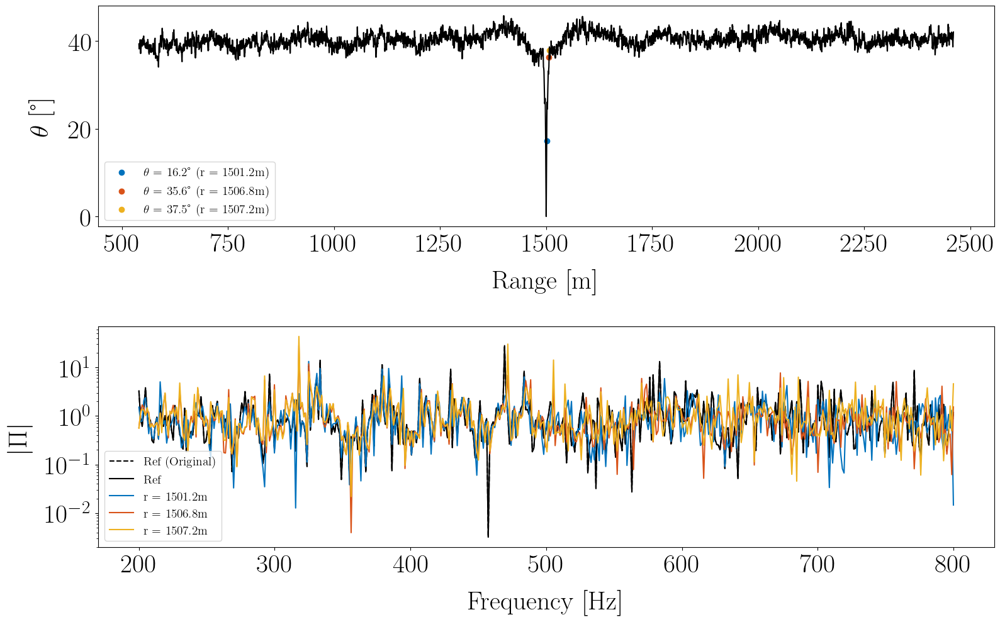

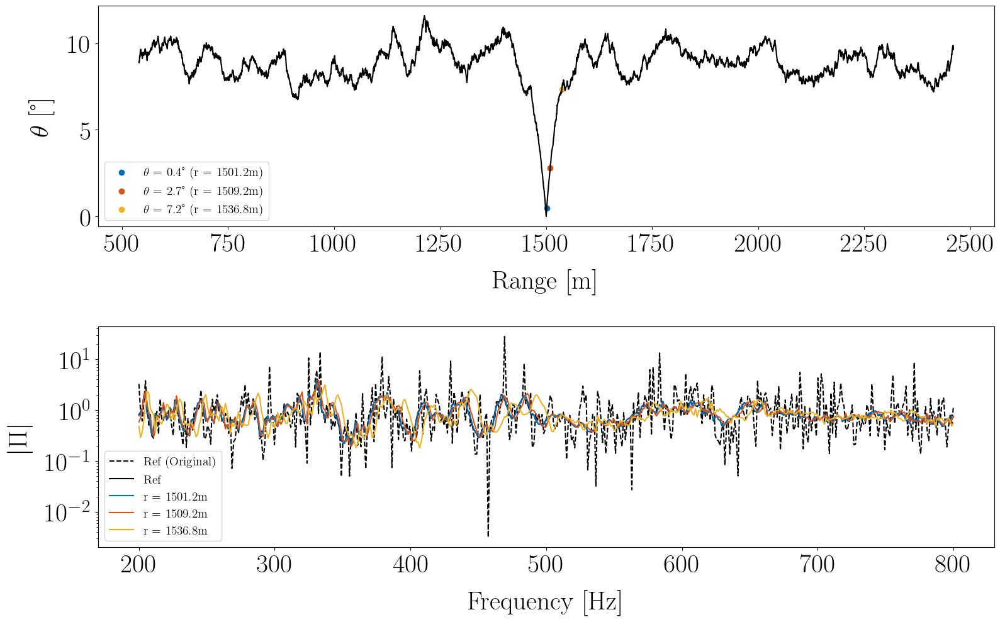

In [35]:
plot_dist_ref_pos(ds, r_valid, dist1_crop)
plot_dist_ref_pos(ds_smooth, r_valid, dist2_crop)

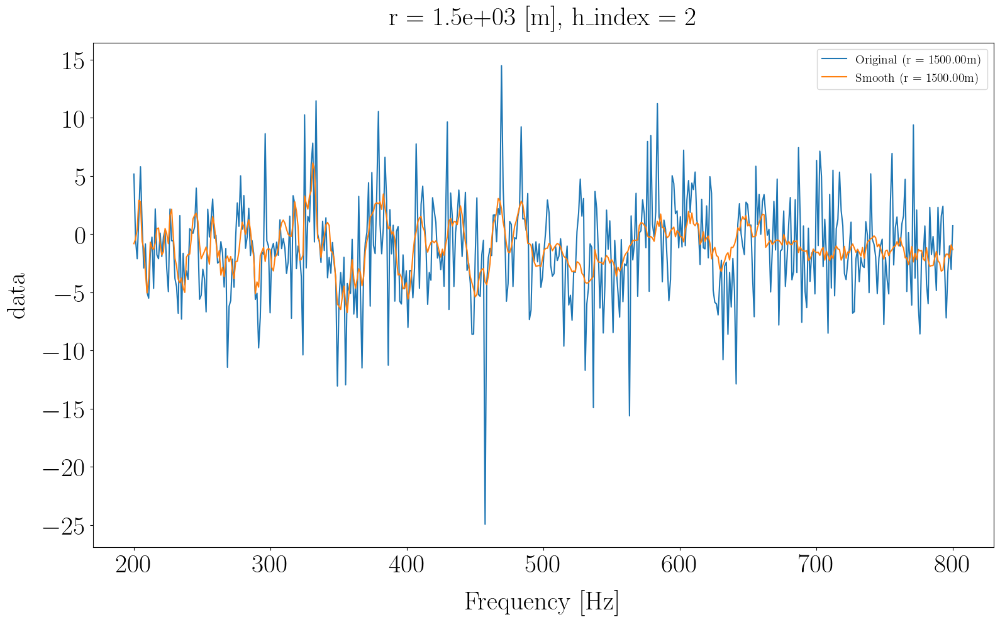

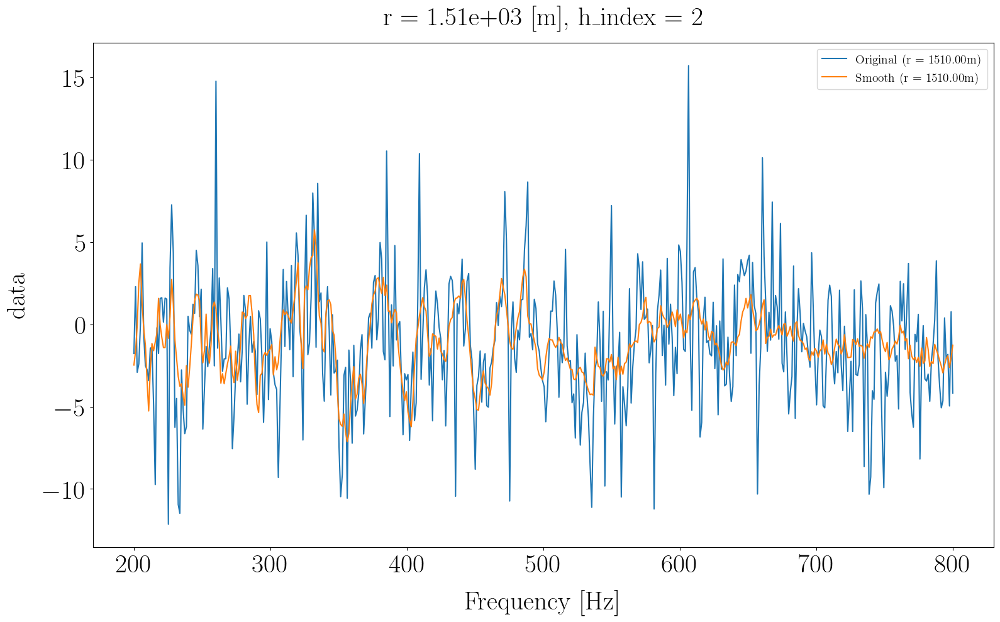

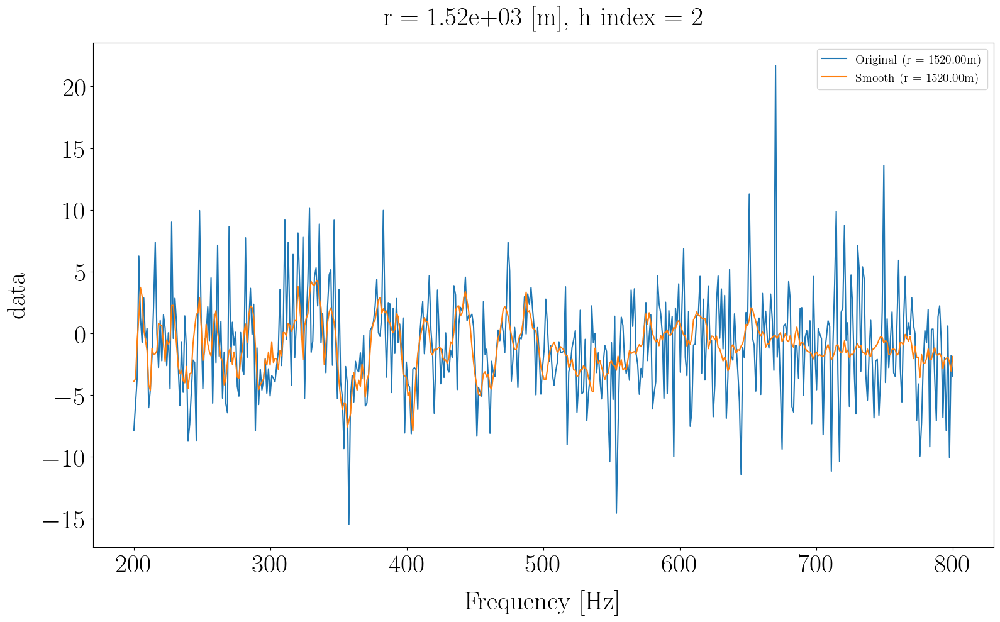

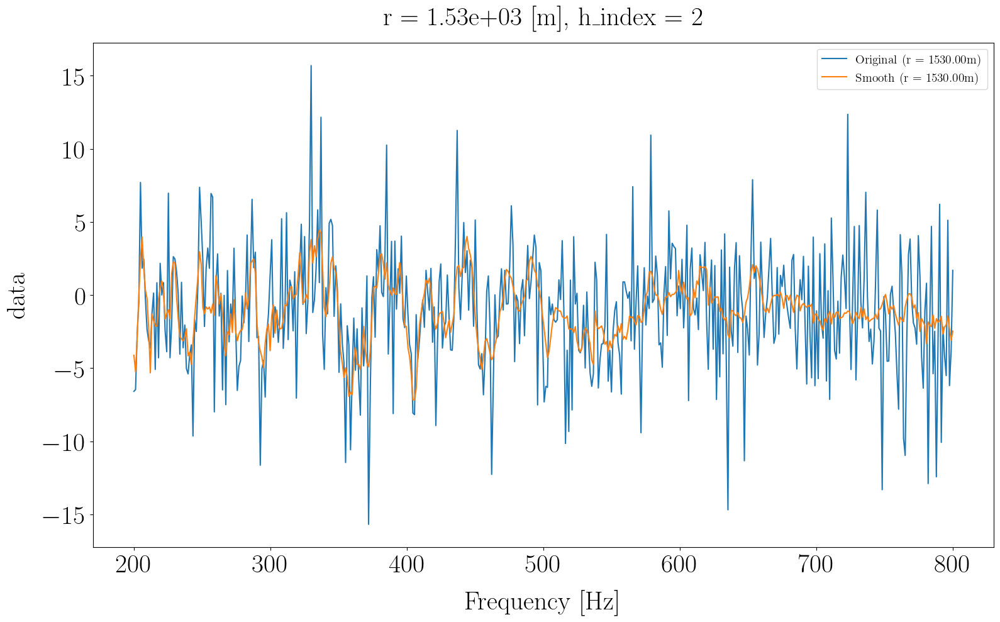

In [36]:
before_smooth = 10 * np.log10(np.abs(ds.data.sel(h_index=2)))
after_smooth = 10 * np.log10(np.abs(ds_smooth.data.sel(h_index=2)))

sel_ranges = [ds.r_ref, ds.r_ref+10, ds.r_ref+20, ds.r_ref+30]
for i_rs, rs in enumerate(sel_ranges):
    before_smooth_rs = before_smooth.sel(r=rs, method="nearest")
    after_smooth_rs = after_smooth.sel(r=rs, method="nearest")

    plt.figure()
    before_smooth_rs.plot(x="f", label=f"Original (r = {before_smooth_rs.r.values:.2f}m)")
    after_smooth_rs.plot(x="f", label=f"Smooth (r = {after_smooth_rs.r.values:.2f}m)")
    # plt.xscale("log")
    plt.legend()

On voit bien ici l'effet du filtrage, les structures sont préservées en tenant compte de la variabilité en espace de la grandeur mesurée. 


# Mesure d'intercorrélation après filtrage 

In [37]:
from misc import cast_matrix_to_target_shape


def plot_intercorr_mat(ds_rtf):
    rtf = ds_rtf.data.values[..., np.newaxis]  # (nrcv, nf, nr, 1)
    rtf_ref = ds_rtf.data_ref.values  # (nrcv, nf)
    rtf_ref_expanded = cast_matrix_to_target_shape(
        rtf_ref, rtf.shape
    )  # (nrcv, nf, nr, 1)

    df = ds_rtf.f.values[1] - ds.f.values[0]
    # Compute dist
    x = np.abs(rtf_ref_expanded)
    y = np.abs(rtf)


    delta_f = sp.correlation_lags(x.shape[1], y.shape[1], mode="full") * df

    n = x.shape[1]
    nfft = 2 * n - 1  # Zero pad to compute full correlation

    x_fft = np.fft.fft(x, n=nfft, axis=1)
    y_fft = np.fft.fft(y, n=nfft, axis=1)

    c_xy = np.fft.ifft(x_fft * np.conj(y_fft), axis=1)
    c_xy = np.real(c_xy)
    d_intercorr = np.fft.fftshift(c_xy, axes=1)

    # c_xx = np.fft.ifft(x_fft * np.conj(x_fft), axis=1)
    # c_yy = np.fft.ifft(y_fft * np.conj(y_fft), axis=1)
    # c_xx_0 = c_xx[:, 0:1, :, :]
    # c_yy_0 = c_yy[:, 0:1, :, :]
    # c_xy_normalized = c_xy / np.sqrt(c_xx_0 * c_yy_0)
    # d_intercorr = np.fft.fftshift(np.real(c_xy_normalized), axes=1)

    d_intercorr_mat = d_intercorr[1, :, :, 0]  # (nf, nr)

    plt.figure()
    vmin = np.percentile(d_intercorr_mat, 5)
    vmax = np.percentile(d_intercorr_mat, 99)
    im = plt.pcolormesh(
        delta_f,
        ds_rtf.r.values,
        d_intercorr_mat.T,
        vmin=vmin,
        vmax=vmax,
        cmap="jet",
    )
    plt.colorbar(im)
    # plt.legend()
    plt.xlabel(r"$\delta_f$")
    plt.ylabel("Range [m]")
    plt.title("Intercorrelation matrix computed with FFT")

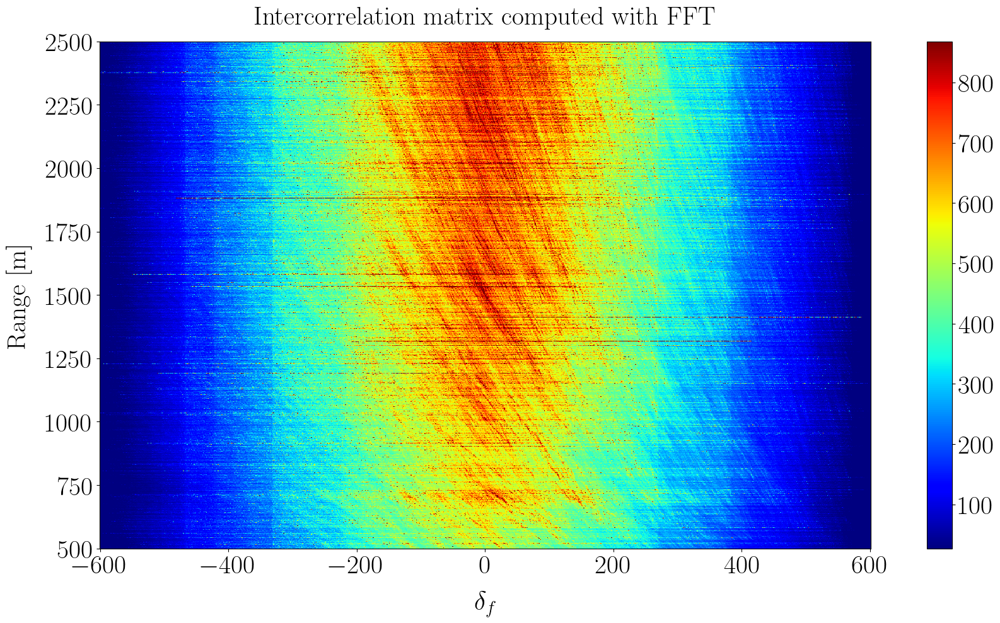

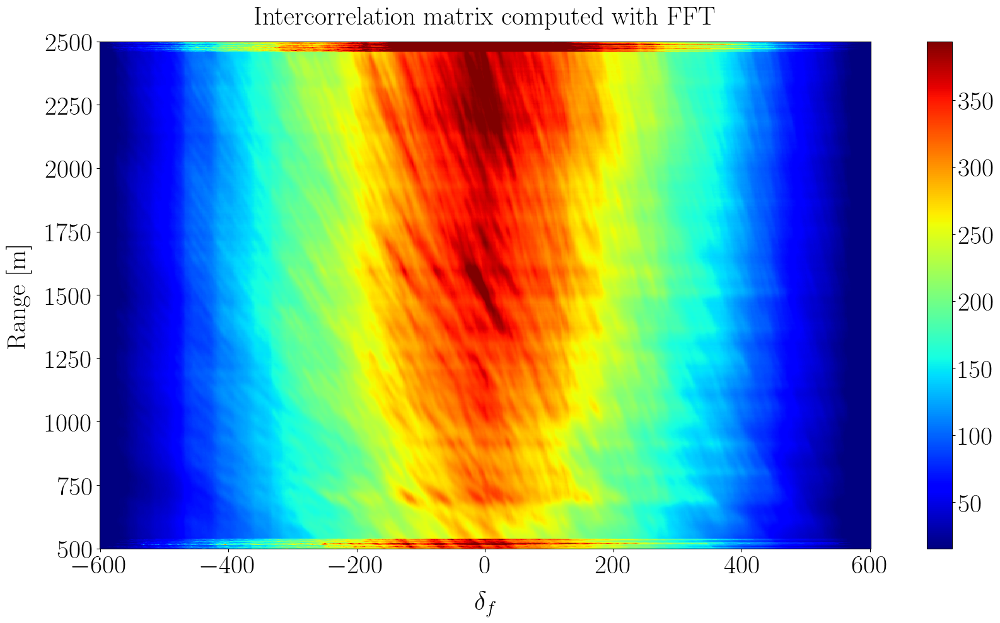

In [38]:
plot_intercorr_mat(ds_rtf=ds)
plot_intercorr_mat(ds_rtf=ds_smooth)

In [39]:
distances = ["intercorr_max"]
dist1 = get_dist(ds, distances=distances)
dist2 = get_dist(ds_smooth, distances=distances)

# Remove first and last points out of windows
I_q_center_first = 0 * n_overlap_I + P  # P = n_I // 2
I_q_center_last = (Q - 1) * n_overlap_I + P  # P = n_I // 2
# print(I_q_center_first, I_q_center_last)


d1 = dist1["intercorr_max"]["d"][I_q_center_first : I_q_center_last + 1]
d2 = dist2["intercorr_max"]["d"][I_q_center_first : I_q_center_last + 1]
r_valid = ds.r.values[I_q_center_first : I_q_center_last + 1]


# Modify to get a distance
d1 = (d1 - d1.min()) / (d1.max() - d1.min())
d1 = 1 - d1
d2 = (d2 - d2.min()) / (d2.max() - d2.min())
d2 = 1 - d2
# print(d1.shape)
# print(d2.shape)
import copy

# dist1_crop = dist1.copy()
dist1_crop = copy.deepcopy(dist1)
dist1_crop["intercorr_max"]["d"] = d1
# dist2_crop = dist2.copy()
dist2_crop = copy.deepcopy(dist2)
dist2_crop["intercorr_max"]["d"] = d2

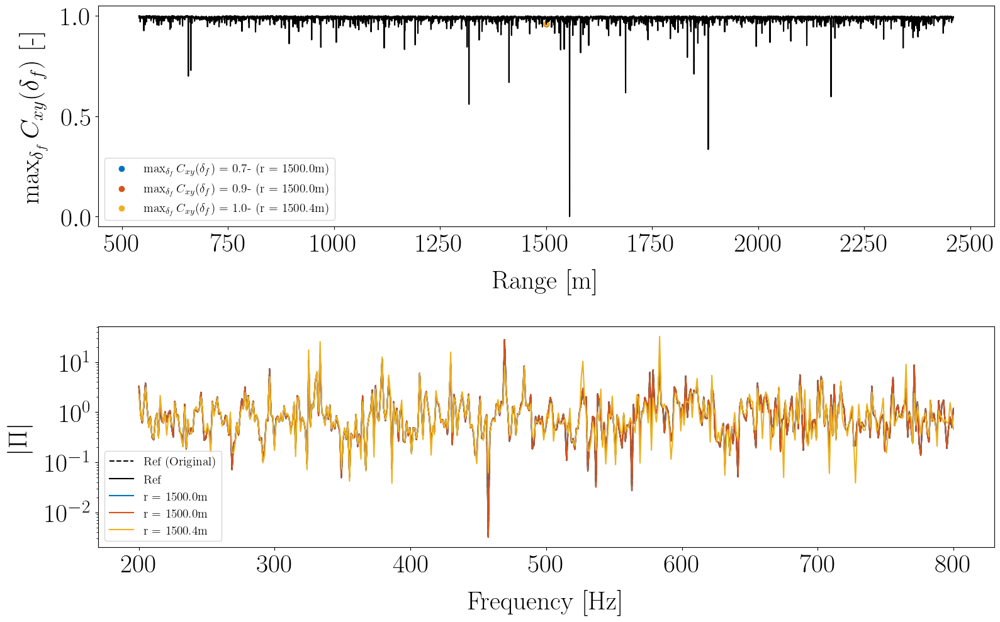

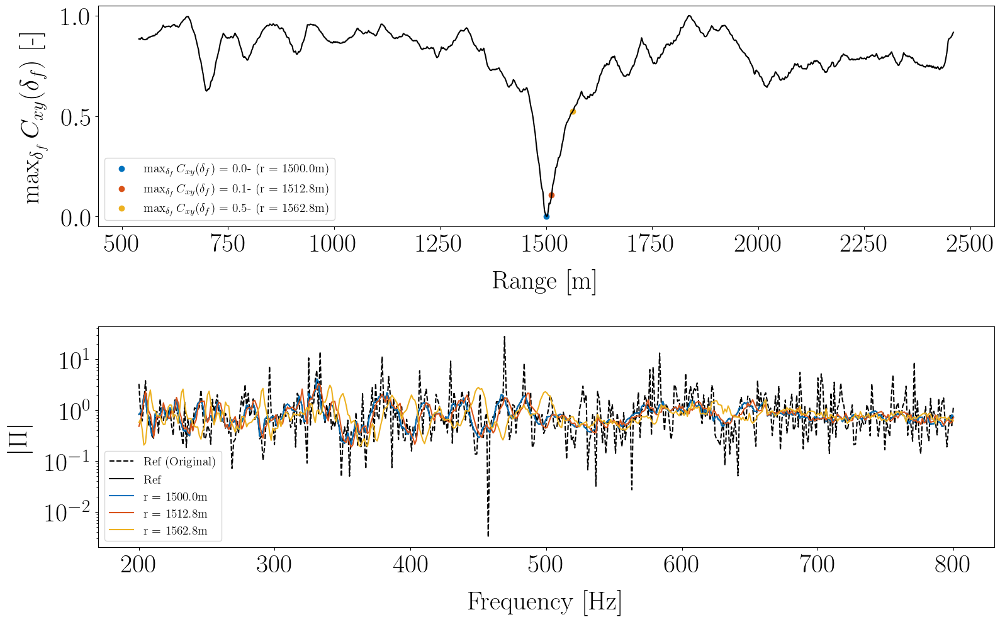

In [40]:
plot_dist_ref_pos(ds, r_valid, dist1_crop)
plot_dist_ref_pos(ds_smooth, r_valid, dist2_crop)